# **YOLOv8 Duygu Tanıma Modelinde Hata Riskinin İkinci Bir Model İle Tahmin Edilmesi**

YOLOv8 kullanarak özelleştirdiğim modelin (Duygu tanıma modeli) dosya içeriğini okuma

In [ ]:
import zipfile

zip_path = "/content/drive/MyDrive/emotions56.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    for name in zip_ref.namelist()[:30]:
        print(name)

images/train/
images/train/10Exp0angry_actor_150.jpg
images/train/12Exp0angry_actor_16.jpg
images/train/1455Exp0angry_girl_299.jpg
images/train/1456Exp0angry_girl_3.jpg
images/train/1457Exp0angry_girl_303.jpg
images/train/1458Exp0angry_girl_308.jpg
images/train/1461Exp0angry_girl_314.jpg
images/train/1463Exp0angry_girl_32.jpg
images/train/1465Exp0angry_girl_327.jpg
images/train/1467Exp0angry_girl_338.jpg
images/train/1468Exp0angry_girl_342.jpg
images/train/1469Exp0angry_girl_349.jpg
images/train/1470Exp0angry_girl_352.jpg
images/train/1473Exp0angry_girl_38.jpg
images/train/1474Exp0angry_girl_383.jpg
images/train/1478Exp0angry_girl_394.jpg
images/train/1480Exp0angry_girl_399.jpg
images/train/1483Exp0angry_girl_411.jpg
images/train/1484Exp0angry_girl_412.jpg
images/train/1485Exp0angry_girl_414.jpg
images/train/1486Exp0angry_girl_419.jpg
images/train/1488Exp0angry_girl_465.jpg
images/train/1489Exp0angry_girl_47.jpg
images/train/1490Exp0angry_girl_470.jpg
images/train/1494Exp0angry_girl_53

Dosya türlerini çıkarma

In [ ]:
from collections import Counter
import os

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    files = zip_ref.namelist()

    extensions = Counter(
        os.path.splitext(f)[1].lower()
        for f in files
        if not f.endswith("/")
    )

    print("Toplam dosya:", sum(extensions.values()))
    print("\nDosya türleri:")

    for ext, count in extensions.items():
        print(f"{ext or 'Uzantısız'}: {count}")

Toplam dosya: 16966

Dosya türleri:
.jpg: 2927
.png: 5553
.cache: 1
.txt: 8480
.pt: 2
.py: 2
.yaml: 1


test.py ve train.py içerikleri gösterimi

In [ ]:
import zipfile

zip_path = "/content/drive/MyDrive/emotions56.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:

    all_files = zip_ref.namelist()

    # Python dosyalarını incele
    for file in all_files:
        if file.endswith(("train.py", "test.py")):
            print(f"\n{'=' * 50}")
            print(f"DOSYA: {file}")
            print('=' * 50)

            content = zip_ref.read(file).decode(
                "utf-8",
                errors="replace"
            )

            print(content[:5000])

    # Bir eğitim etiketini incele
    label_files = [
        f for f in all_files
        if "/labels/train/" in f and f.endswith(".txt")
    ]

    if label_files:
        print("\nÖRNEK ETİKET:")
        print(label_files[0])
        print(zip_ref.read(label_files[0]).decode("utf-8"))


DOSYA: test.py
from ultralytics import YOLO
model = YOLO("500epochs.pt")
result = model.predict("D:/emotions56/test",save=True)
#print(result)
#model.predict('https://youtu.be/5kEnotoDnEY?list=RDCMUCgc3VJYdM_R8oKGRuXxUbKQ', imgsz=416, save=True)


DOSYA: train.py
from ultralytics import YOLO

model = YOLO("yolov8n.yaml")
results= model.train(data="label56.yaml",epochs=500,conf=0.8,augment=True,cos_lr=True,batch=8)

#train epochs=300,conf=0.75
#train2 epochs=500,conf=0.8,augmentation=True,cos_lr=True,batch=8


YOLOv8 modeli için kullandığım test verilerinin içeriği

In [ ]:
import zipfile

zip_path = "/content/drive/MyDrive/emotions56.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    files = z.namelist()

    print("ZIP içerisindeki ilk 50 kayıt:\n")

    for f in files[:50]:
        print(f)

    print("\nTEST içeren dosya yolları:\n")

    test_files = [
        f for f in files
        if "test" in f.lower()
    ]

    for f in test_files[:100]:
        print(f)

    print("\nTest ile ilişkili toplam kayıt:", len(test_files))

ZIP içerisindeki ilk 50 kayıt:

images/train/
images/train/10Exp0angry_actor_150.jpg
images/train/12Exp0angry_actor_16.jpg
images/train/1455Exp0angry_girl_299.jpg
images/train/1456Exp0angry_girl_3.jpg
images/train/1457Exp0angry_girl_303.jpg
images/train/1458Exp0angry_girl_308.jpg
images/train/1461Exp0angry_girl_314.jpg
images/train/1463Exp0angry_girl_32.jpg
images/train/1465Exp0angry_girl_327.jpg
images/train/1467Exp0angry_girl_338.jpg
images/train/1468Exp0angry_girl_342.jpg
images/train/1469Exp0angry_girl_349.jpg
images/train/1470Exp0angry_girl_352.jpg
images/train/1473Exp0angry_girl_38.jpg
images/train/1474Exp0angry_girl_383.jpg
images/train/1478Exp0angry_girl_394.jpg
images/train/1480Exp0angry_girl_399.jpg
images/train/1483Exp0angry_girl_411.jpg
images/train/1484Exp0angry_girl_412.jpg
images/train/1485Exp0angry_girl_414.jpg
images/train/1486Exp0angry_girl_419.jpg
images/train/1488Exp0angry_girl_465.jpg
images/train/1489Exp0angry_girl_47.jpg
images/train/1490Exp0angry_girl_470.jpg
im

YOLOv8 modelinin test verilerinin içerik ve sınıf kontrolü

In [ ]:
import zipfile
import os
from collections import Counter

zip_path = "/content/drive/MyDrive/emotions56.zip"

class_names = {
    0: "anger",
    1: "contempt",
    2: "disgust",
    3: "fear",
    4: "happiness",
    5: "neutrality",
    6: "sadness",
    7: "surprise"
}

with zipfile.ZipFile(zip_path, "r") as z:

    files = z.namelist()

    test_images = [
        f for f in files
        if f.startswith("test/images/")
        and f.lower().endswith((".png", ".jpg", ".jpeg"))
    ]

    test_labels = [
        f for f in files
        if f.startswith("test/labels/")
        and f.lower().endswith(".txt")
    ]

    image_names = {
        os.path.splitext(os.path.basename(f))[0]
        for f in test_images
    }

    label_names = {
        os.path.splitext(os.path.basename(f))[0]
        for f in test_labels
    }

    print("TEST VERİ SETİ")
    print("-" * 40)

    print("Görüntü sayısı:", len(test_images))
    print("Etiket sayısı:", len(test_labels))

    print("\nEtiketi eksik görüntüler:")
    print(image_names - label_names)

    print("\nGörüntüsü eksik etiketler:")
    print(label_names - image_names)

    classes = Counter()
    invalid_labels = []
    box_counts = Counter()

    for label_file in test_labels:

        content = z.read(label_file).decode("utf-8").strip()

        if not content:
            invalid_labels.append(label_file)
            continue

        lines = content.splitlines()
        box_counts[len(lines)] += 1

        for line in lines:

            values = line.split()

            if len(values) != 5:
                invalid_labels.append(label_file)
                continue

            class_id = int(float(values[0]))

            if class_id not in class_names:
                invalid_labels.append(label_file)
                continue

            classes[class_id] += 1

    print("\nSINIF DAĞILIMI")
    print("-" * 40)

    for class_id, name in class_names.items():
        print(f"{name}: {classes[class_id]}")

    print("\nBounding box sayıları:", dict(box_counts))
    print("Hatalı etiket dosyaları:", invalid_labels)

    print("\nEşleşme kontrolü:",
          "BAŞARILI" if image_names == label_names else "HATALI")

TEST VERİ SETİ
----------------------------------------
Görüntü sayısı: 160
Etiket sayısı: 160

Etiketi eksik görüntüler:
set()

Görüntüsü eksik etiketler:
set()

SINIF DAĞILIMI
----------------------------------------
anger: 20
contempt: 20
disgust: 20
fear: 20
happiness: 20
neutrality: 20
sadness: 20
surprise: 20

Bounding box sayıları: {1: 160}
Hatalı etiket dosyaları: []

Eşleşme kontrolü: BAŞARILI


Modeli kullanabilmemiz için gerekli kütüphane

In [ ]:
!pip -q install ultralytics

Duygu tanıma modeli için kullandığım iki AI modeli (Biri yüz tanıma diğeri duygu tanıma) *Dipnot: Bu içerikte yüz tanıma kullanılmamıştır.*

In [ ]:
import os
import zipfile

zip_path = "/content/drive/MyDrive/emotions56.zip"
extract_path = "/content/emotions56"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Veri seti başarıyla çıkartıldı.")

print("\nModel dosyaları:")

for file in os.listdir(extract_path):
    if file.endswith(".pt"):
        print(file)

Veri seti başarıyla çıkartıldı.

Model dosyaları:
yolov8n-emo.pt
yolo26n-face.pt


Duygu tanıma modeli görevi ve sınıfları

In [ ]:
from ultralytics import YOLO

model_path = "/content/emotions56/yolov8n-emo.pt"

model = YOLO(model_path)

print("Model görevi:", model.task)
print("Model sınıfları:", model.names)

Model görevi: detect
Model sınıfları: {0: 'anger', 1: 'contempt', 2: 'disgust', 3: 'fear', 4: 'happiness', 5: 'neutrality', 6: 'sadness', 7: 'surprise'}


Test verilerinin içerik dağılımı

In [ ]:

from pathlib import Path
from collections import Counter

images_dir = Path("/content/emotions56/test/images")
labels_dir = Path("/content/emotions56/test/labels")

class_names = {
    0: "anger",
    1: "contempt",
    2: "disgust",
    3: "fear",
    4: "happiness",
    5: "neutrality",
    6: "sadness",
    7: "surprise"
}

images = sorted([
    p for p in images_dir.iterdir()
    if p.suffix.lower() in [".png", ".jpg", ".jpeg"]
])

class_counts = Counter()
prefix_counts = Counter()
anger_files = []

for img in images:
    label_path = labels_dir / f"{img.stem}.txt"

    if not label_path.exists():
        continue

    with open(label_path) as f:
        class_id = int(f.readline().split()[0])

    class_counts[class_names[class_id]] += 1

    prefix = img.stem.rstrip("0123456789")
    prefix_counts[prefix] += 1

    if class_id == 0:
        anger_files.append(img.name)

print("TOPLAM GÖRÜNTÜ:", len(images))

print("\nSINIF DAĞILIMI")
for name, count in class_counts.items():
    print(f"{name}: {count}")

print("\nDOSYA İSİM GRUPLARI")
for name, count in prefix_counts.items():
    print(f"{name}: {count}")

print("\nANGER GÖRÜNTÜLERİ")
print(anger_files)


TOPLAM GÖRÜNTÜ: 160

SINIF DAĞILIMI
anger: 20
contempt: 20
disgust: 20
fear: 20
happiness: 20
neutrality: 20
sadness: 20
surprise: 20

DOSYA İSİM GRUPLARI
anger: 20
contempt: 20
disgust: 20
fear: 20
happy: 20
neutral: 20
sad: 20
surprise: 20

ANGER GÖRÜNTÜLERİ
['anger001.png', 'anger003.png', 'anger10015.png', 'anger1013.png', 'anger10283.png', 'anger1033.png', 'anger10352.png', 'anger10414.png', 'anger10440.png', 'anger10451.png', 'anger1056.png', 'anger10562.png', 'anger10571.png', 'anger1058.png', 'anger10644.png', 'anger10659.png', 'anger10665.png', 'anger10695.png', 'anger10805.png', 'anger10809.png']


Duygu tanıma modeli ile test verilerinin karşılaştırılması

Toplam görüntü: 160
Doğru tahmin: 111
Yanlış tahmin: 49


,image_name,true_emotion,predicted_emotion,true_class,predicted_class,yolo_confidence,correct
0,anger001.png,anger,surprise,0,7,0.661676,False
1,anger003.png,anger,anger,0,0,0.990852,True
2,anger10015.png,anger,contempt,0,1,0.711389,False
3,anger1013.png,anger,disgust,0,2,0.760580,False
4,anger10283.png,anger,fear,0,3,0.624026,False
...,...,...,...,...,...,...,...
155,surprise10831.png,surprise,surprise,7,7,0.936975,True
156,surprise10863.png,surprise,surprise,7,7,0.993352,True
157,surprise10914.png,surprise,surprise,7,7,0.981896,True
158,surprise10929.png,surprise,surprise,7,7,0.753305,True


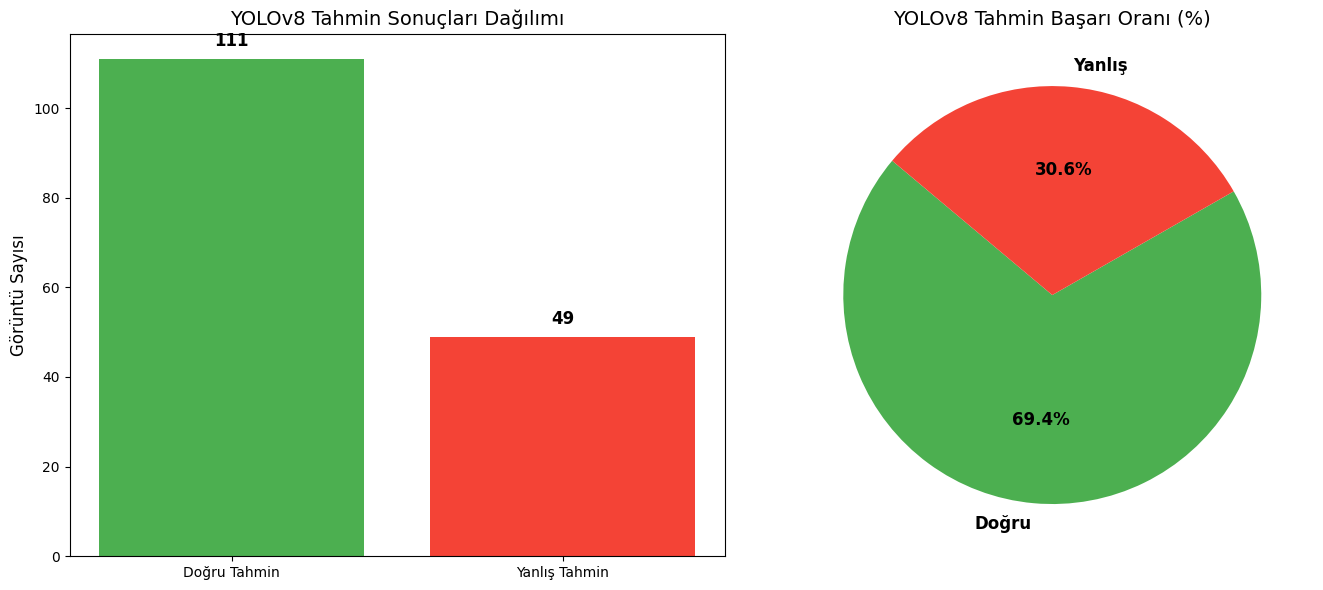

In [ ]:
import os
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

test_images_path = "/content/emotions56/test/images"
test_labels_path = "/content/emotions56/test/labels"

# Test görüntülerini listele
image_paths = sorted([
    str(p) for p in Path(test_images_path).iterdir()
    if p.suffix.lower() in [".png", ".jpg", ".jpeg"]
])

# Model ile tahmin yap
results = model.predict(
    source=image_paths,
    conf=0.001,
    save=False,
    verbose=False
)

predictions = []

for result in results:

    image_name = Path(result.path).name
    label_path = os.path.join(
        test_labels_path,
        Path(image_name).stem + ".txt"
    )

    # Gerçek sınıfı oku
    with open(label_path, "r") as f:
        true_class = int(f.readline().split()[0])

    # Model tahmini
    if result.boxes is not None and len(result.boxes) > 0:

        best_index = result.boxes.conf.argmax()

        predicted_class = int(
            result.boxes.cls[best_index].item()
        )

        confidence = float(
            result.boxes.conf[best_index].item()
        )

    else:
        predicted_class = -1
        confidence = 0.0

    predictions.append({
        "image_name": image_name,
        "true_emotion": model.names[true_class],
        "predicted_emotion": (
            model.names[predicted_class]
            if predicted_class != -1
            else "no_detection"
        ),
        "true_class": true_class,
        "predicted_class": predicted_class,
        "yolo_confidence": confidence,
        "correct": true_class == predicted_class
    })

df = pd.DataFrame(predictions)

print("Toplam görüntü:", len(df))
print("Doğru tahmin:", df["correct"].sum())
print("Yanlış tahmin:", (~df["correct"]).sum())

display(df)

# --- GRAFİKLEŞTİRME BÖLÜMÜ ---
correct_count = df["correct"].sum()
incorrect_count = (~df["correct"]).sum()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 1. Sütun Grafiği (Bar Plot)
axes[0].bar(["Doğru Tahmin", "Yanlış Tahmin"], [correct_count, incorrect_count], color=["#4CAF50", "#F44336"])
axes[0].set_title("YOLOv8 Tahmin Sonuçları Dağılımı", fontsize=14)
axes[0].set_ylabel("Görüntü Sayısı", fontsize=12)
for i, val in enumerate([correct_count, incorrect_count]):
    axes[0].text(i, val + 2, str(val), ha='center', va='bottom', fontsize=12, fontweight='bold')

# 2. Pasta Grafiği (Pie Chart)
axes[1].pie(
    [correct_count, incorrect_count],
    labels=["Doğru", "Yanlış"],
    autopct="%1.1f%%",
    startangle=140,
    colors=["#4CAF50", "#F44336"],
    textprops={'fontsize': 12, 'weight': 'bold'}
)
axes[1].set_title("YOLOv8 Tahmin Başarı Oranı (%)", fontsize=14)

plt.tight_layout()
plt.show()

Sınıf Bazlı Performans Değerlendirmesi

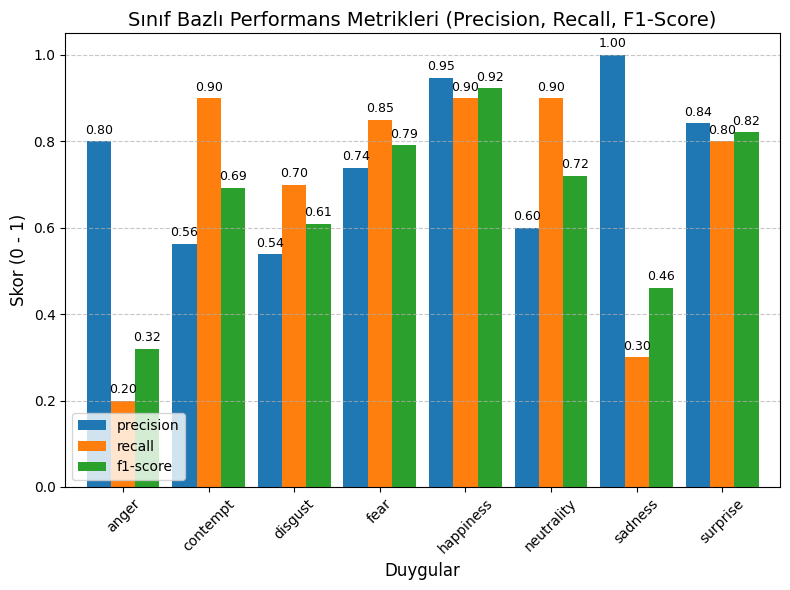

In [ ]:
from sklearn.metrics import classification_report
import pandas as pd
import matplotlib.pyplot as plt

# Sınıf isimlerini alalım
target_names = [model.names[i] for i in sorted(model.names.keys())]

# Sınıflandırma raporunu alalım
report = classification_report(
    df["true_class"],
    df["predicted_class"],
    labels=list(model.names.keys()),
    target_names=target_names,
    output_dict=True
)

# DataFrame'e dönüştürüp sadece sınıfları filtreleyelim (accuracy ve avg satırlarını hariç tutuyoruz)
report_df = pd.DataFrame(report).transpose()
metrics_df = report_df.loc[target_names, ["precision", "recall", "f1-score"]]

# Matplotlib ile görselleştirme
ax = metrics_df.plot(kind="bar", figsize=(8, 6), width=0.85)
plt.title("Sınıf Bazlı Performans Metrikleri (Precision, Recall, F1-Score)", fontsize=14)
plt.xlabel("Duygular", fontsize=12)
plt.ylabel("Skor (0 - 1)", fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.legend(loc="lower left")
plt.ylim(0, 1.05)

# Çubukların üzerine değerleri yazdıralım
for p in ax.patches:
    ax.annotate(f"{p.get_height():.2f}",
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center',
                xytext=(0, 8),
                textcoords='offset points',
                fontsize=9)

plt.tight_layout()
plt.show()

Sınıf bazlı confusion matrix

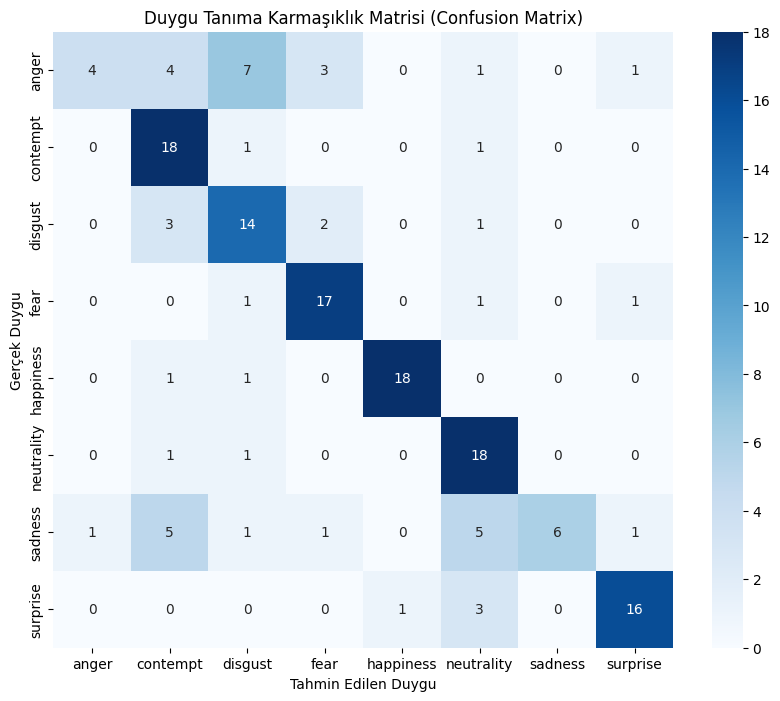

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Karmaşıklık Matrisini Görselleştirme
cm = confusion_matrix(
    df["true_class"],
    df["predicted_class"],
    labels=list(model.names.keys())
)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=target_names,
    yticklabels=target_names
)
plt.title("Duygu Tanıma Karmaşıklık Matrisi (Confusion Matrix)")
plt.ylabel("Gerçek Duygu")
plt.xlabel("Tahmin Edilen Duygu")
plt.show()

YOLOv8 modelinin test verileri ve label karşılaştırmasının yüzde olarak doğruluğu

In [ ]:
accuracy = df["correct"].mean()

print(f"Model doğruluğu: %{accuracy * 100:.2f}")

Model doğruluğu: %69.38


En çok karıştırılan **anger** etiketinin karıştırıldığı duygu etiketleri ve confidence skorları

Yanlış anger tahminleri sayısı: 16


,image_name,predicted_emotion,yolo_confidence
0,anger001.png,surprise,0.661676
2,anger10015.png,contempt,0.711389
3,anger1013.png,disgust,0.760580
4,anger10283.png,fear,0.624026
5,anger1033.png,neutrality,0.783800
6,anger10352.png,contempt,0.654027
7,anger10414.png,contempt,0.942455
8,anger10440.png,contempt,0.945646
9,anger10451.png,disgust,0.972737
11,anger10562.png,fear,0.985501


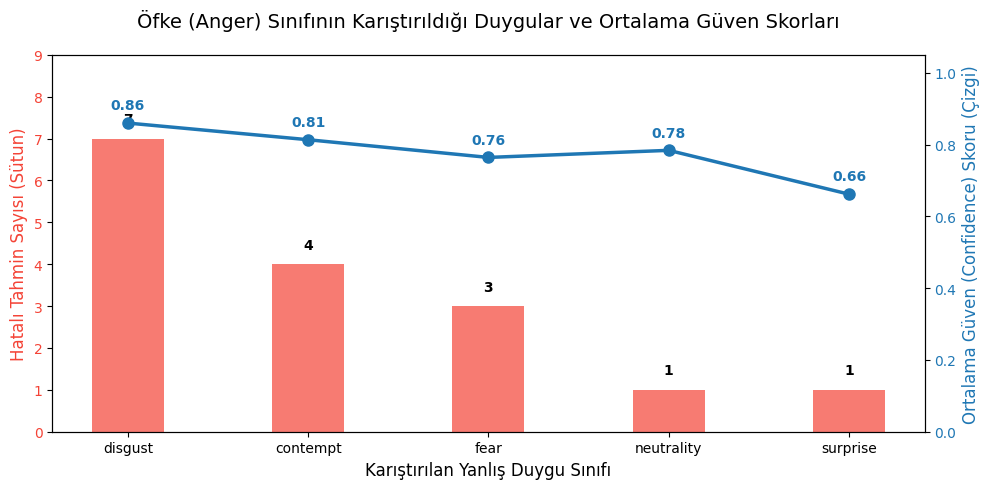

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Duygu sınıfı haritası
class_names = {
    0: "anger",
    1: "contempt",
    2: "disgust",
    3: "fear",
    4: "happiness",
    5: "neutrality",
    6: "sadness",
    7: "surprise"
}

# Yanlış 'anger' tahminlerini filtrele (anger true_class = 0, doğru tahmin edilmediyse correct = False)
anger_errors = df[
    (df["true_class" ] == 0) &
    (df["correct"] == False)
].copy()

# Gerekli kolonları metin formatına çevirelim
if len(anger_errors) > 0:
    anger_errors["true_emotion"] = anger_errors["true_class"].map(class_names)
    anger_errors["predicted_emotion"] = anger_errors["predicted_class"].map(class_names)

print("Yanlış anger tahminleri sayısı:", len(anger_errors))
if len(anger_errors) > 0:
    display(
        anger_errors[
            ["image_name", "predicted_emotion", "yolo_confidence"]
        ]
    )

# --- GRAFİKLEŞTİRME ---
if len(anger_errors) > 0:
    # Yanlış tahmin edilen sınıfların frekansını ve ortalama güven skorunu hesapla
    error_summary = anger_errors.groupby("predicted_emotion").agg(
        count=("image_name", "count"),
        mean_confidence=("yolo_confidence", "mean")
    ).reset_index().sort_values(by="count", ascending=False)

    fig, ax1 = plt.subplots(figsize=(10, 5))

    # 1. Bar Plot - Yanlış tahmin edilen sınıf sayıları
    color = '#F44336'
    ax1.set_xlabel('Karıştırılan Yanlış Duygu Sınıfı', fontsize=12)
    ax1.set_ylabel('Hatalı Tahmin Sayısı (Sütun)', color=color, fontsize=12)
    bars = ax1.bar(error_summary["predicted_emotion"], error_summary["count"], color=color, alpha=0.7, width=0.4)
    ax1.tick_params(axis='y', labelcolor=color)
    ax1.set_ylim(0, error_summary["count"].max() + 2)

    # Sütun değerlerini yazdır
    for bar in bars:
        yval = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2.0, yval + 0.3, str(int(yval)), ha='center', va='bottom', fontweight='bold')

    # 2. Line Plot - Ortalama Güven Skoru
    ax2 = ax1.twinx()
    color = '#1f77b4'
    ax2.set_ylabel('Ortalama Güven (Confidence) Skoru (Çizgi)', color=color, fontsize=12)
    ax2.plot(error_summary["predicted_emotion"], error_summary["mean_confidence"], color=color, marker='o', linewidth=2.5, markersize=8)
    ax2.tick_params(axis='y', labelcolor=color)
    ax2.set_ylim(0, 1.05)

    # Çizgi üzerindeki değerleri yazdır
    for idx, row in error_summary.iterrows():
        ax2.text(row["predicted_emotion"], row["mean_confidence"] + 0.03, f"{row['mean_confidence']:.2f}", ha='center', va='bottom', color=color, fontweight='bold')

    plt.title("Öfke (Anger) Sınıfının Karıştırıldığı Duygular ve Ortalama Güven Skorları", fontsize=14, pad=20)
    plt.tight_layout()
    plt.show()
else:
    print("Öfke (anger) sınıfında yanlış tahmin bulunamadı.")

En çok karıştırılan **anger** etiketinin hangi duygularla karşılaştırıldığının tablosu

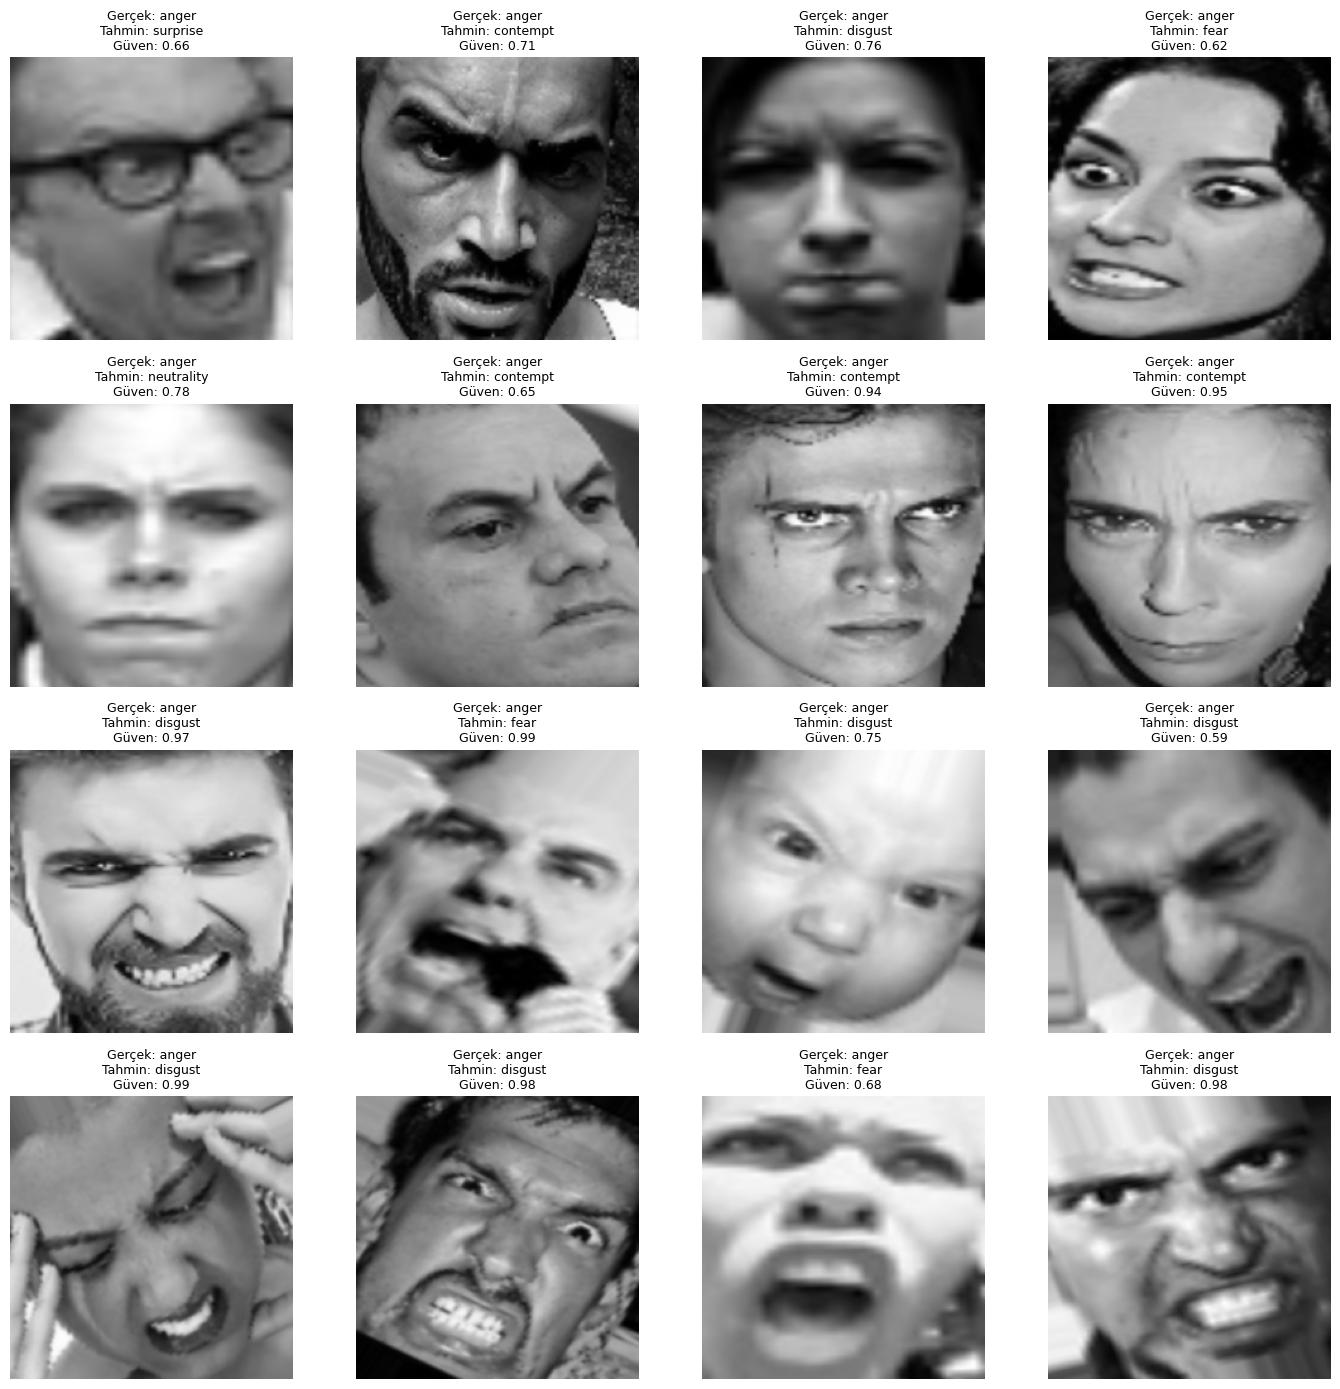

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

anger_errors = df[
    (df["true_emotion"] == "anger") &
    (~df["correct"])
]

fig, axes = plt.subplots(4, 4, figsize=(14, 14))
axes = axes.flatten()

for ax, (_, row) in zip(axes, anger_errors.iterrows()):
    image_path = Path(test_images_path) / row["image_name"]
    image = Image.open(image_path).convert("RGB")

    ax.imshow(image)
    ax.set_title(
        f"Gerçek: anger\n"
        f"Tahmin: {row['predicted_emotion']}\n"
        f"Güven: {row['yolo_confidence']:.2f}",
        fontsize=9
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

Görüntü özelliklerine göre model değerlendirme (brightness, contrast, blur)

Model sınıfları: {0: 'anger', 1: 'contempt', 2: 'disgust', 3: 'fear', 4: 'happiness', 5: 'neutrality', 6: 'sadness', 7: 'surprise'}

Veri seti oluşturuldu!
Toplam görüntü: 160

İlk 5 kayıt:


,image,brightness,blur,contrast,face_size,confidence,predicted_class,true_class,error_risk
0,anger001.png,117.423370,7.808967,45.746452,0.997223,0.661676,7,0,1
1,anger003.png,145.616689,528.093989,62.656864,0.997204,0.990852,0,0,0
2,anger10015.png,87.396584,109.929386,59.634450,0.995763,0.711389,1,0,1
3,anger1013.png,84.428213,7.309006,56.012843,0.995024,0.760580,2,0,1
4,anger10283.png,118.818977,55.443874,69.040938,0.999298,0.624026,3,0,1



Hata dağılımı:
error_risk
0    111
1     49
Name: count, dtype: int64

CSV dosyası: /content/emotion_error_analysis.csv


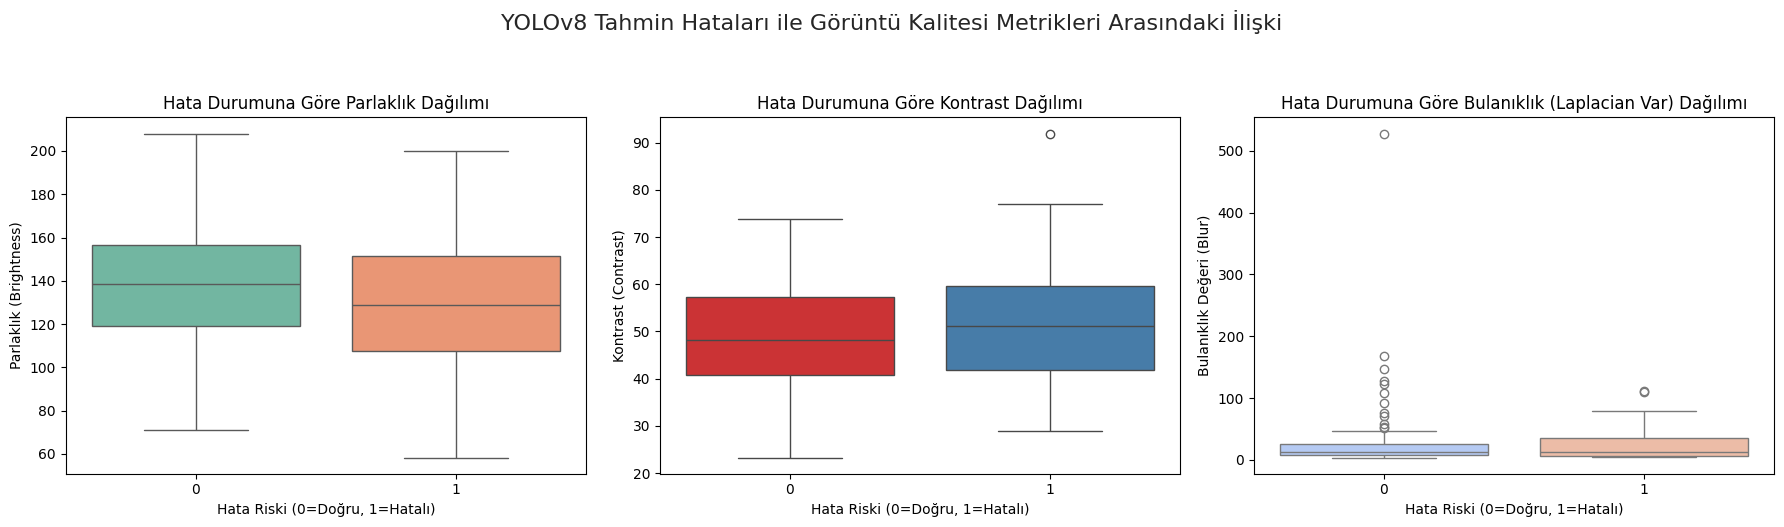

In [ ]:

import cv2
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from ultralytics import YOLO

# --------------------------------------------------
# 1. Dosya yolları
# --------------------------------------------------

zip_path = "/content/drive/MyDrive/emotions56.zip"
model_path = "/content/emotions56/yolov8n-emo.pt"

extract_path = Path("/content/emotions56_test")

# --------------------------------------------------
# 2. Test verilerini çıkar
# --------------------------------------------------

extract_path.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

image_dir = extract_path / "test" / "images"
label_dir = extract_path / "test" / "labels"

# --------------------------------------------------
# 3. Mevcut YOLO modelini yükle
# --------------------------------------------------

model = YOLO(model_path)

print("Model sınıfları:", model.names)

# --------------------------------------------------
# 4. Görüntüleri ve özellikleri incele
# --------------------------------------------------

records = []

image_paths = sorted(image_dir.glob("*.png"))

for image_path in image_paths:

    label_path = label_dir / f"{image_path.stem}.txt"

    if not label_path.exists():
        print("Etiket bulunamadı:", image_path.name)
        continue

    # Gerçek sınıfı oku
    label_values = label_path.read_text().strip().split()

    if not label_values:
        print("Boş etiket:", image_path.name)
        continue

    true_class = int(label_values[0])

    # Görüntüyü oku
    image = cv2.imread(str(image_path))

    if image is None:
        print("Görüntü okunamadı:", image_path.name)
        continue

    height, width = image.shape[:2]
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Görüntü özellikleri
    brightness = float(np.mean(gray))
    contrast = float(np.std(gray))
    blur = float(cv2.Laplacian(
        gray, cv2.CV_64F
    ).var())

    # YOLO tahmini
    result = model.predict(
        source=image,
        conf=0.001,
        iou=0.7,
        verbose=False
    )[0]

    if result.boxes is not None and len(result.boxes) > 0:

        best_index = result.boxes.conf.argmax()

        predicted_class = int(
            result.boxes.cls[best_index].item()
        )

        confidence = float(
            result.boxes.conf[best_index].item()
        )

        # Tahmin edilen yüzün görüntü alanına oranı
        x1, y1, x2, y2 = result.boxes.xyxy[
            best_index
        ].cpu().numpy()

        face_area = max(0, x2 - x1) * max(0, y2 - y1)
        face_size = float(face_area / (width * height))

    else:
        predicted_class = -1
        confidence = 0.0
        face_size = 0.0

    # Tahmin doğru mu?
    error_risk = int(predicted_class != true_class)

    records.append({
        "image": image_path.name,
        "brightness": brightness,
        "blur": blur,
        "contrast": contrast,
        "face_size": face_size,
        "confidence": confidence,
        "predicted_class": predicted_class,
        "true_class": true_class,
        "error_risk": error_risk
    })

# --------------------------------------------------
# 5. DataFrame oluştur ve kaydet
# --------------------------------------------------

df = pd.DataFrame(records)

output_path = "/content/emotion_error_analysis.csv"

df.to_csv(output_path, index=False)

print("\nVeri seti oluşturuldu!")
print("Toplam görüntü:", len(df))
print("\nİlk 5 kayıt:")
display(df.head())

print("\nHata dağılımı:")
print(df["error_risk"].value_counts())

print("\nCSV dosyası:", output_path)

# --------------------------------------------------
# 6. GÖRSELLEŞTİRME ADIMI
# --------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.set_theme(style="whitegrid")

# Grafik 1: Brightness (Parlaklık) Dağılımı
sns.boxplot(ax=axes[0], data=df, x="error_risk", y="brightness", hue="error_risk", palette="Set2", legend=False)
axes[0].set_title("Hata Durumuna Göre Parlaklık Dağılımı")
axes[0].set_xlabel("Hata Riski (0=Doğru, 1=Hatalı)")
axes[0].set_ylabel("Parlaklık (Brightness)")

# Grafik 2: Contrast (Kontrast) Dağılımı
sns.boxplot(ax=axes[1], data=df, x="error_risk", y="contrast", hue="error_risk", palette="Set1", legend=False)
axes[1].set_title("Hata Durumuna Göre Kontrast Dağılımı")
axes[1].set_xlabel("Hata Riski (0=Doğru, 1=Hatalı)")
axes[1].set_ylabel("Kontrast (Contrast)")

# Grafik 3: Blur (Bulanıklık) Dağılımı
sns.boxplot(ax=axes[2], data=df, x="error_risk", y="blur", hue="error_risk", palette="coolwarm", legend=False)
axes[2].set_title("Hata Durumuna Göre Bulanıklık (Laplacian Var) Dağılımı")
axes[2].set_xlabel("Hata Riski (0=Doğru, 1=Hatalı)")
axes[2].set_ylabel("Bulanıklık Değeri (Blur)")

plt.suptitle("YOLOv8 Tahmin Hataları ile Görüntü Kalitesi Metrikleri Arasındaki İlişki", fontsize=16, y=1.05)
plt.tight_layout()
plt.show()


YOLOv8 modelinin genel istatislikleri

In [ ]:
from IPython.display import display, HTML
import pandas as pd

# Başlıkları daha estetik göstermek için yardımcı fonksiyon
def display_title(text):
    display(HTML(f"<h4 style='color: #11111; margin-top: 15px; margin-bottom: 5px; font-family: sans-serif;'>{text}</h4>"))

# 1. Genel İstatistikler Tablosu
display_title("1. Genel İstatistikler")
stats_df = df.describe().round(3)
display(stats_df.style.set_table_styles([
    {'selector': 'th', 'props': [('background-color', '#F2F4F4'), ('color', '#2E4053'), ('font-weight', 'bold')]}
]).format(precision=3))

# 2. Hata Durumuna Göre Ortalamalar
display_title("2. Hata Durumuna Göre Ortalamalar (0: Doğru, 1: Hatalı)")
feature_columns = ["brightness", "blur", "contrast", "face_size", "confidence"]
means_df = df.groupby("error_risk")[feature_columns].mean().round(3)
display(means_df.style.set_table_styles([
    {'selector': 'th', 'props': [('background-color', '#EAECEE'), ('color', '#2E4053'), ('font-weight', 'bold')]}
]).format(precision=3))

# 3. Yüz Büyüklüğü (Face Size) Değerleri Özeti
display_title("3. Face Size (Yüz Büyüklüğü) Özet İstatistikleri")
face_stats = df["face_size"].describe().to_frame().round(4)
face_stats.loc["nunique"] = df["face_size"].nunique()
display(face_stats.style.set_table_styles([
    {'selector': 'th', 'props': [('background-color', '#D5F5E3'), ('color', '#196F3D'), ('font-weight', 'bold')]}
]).format(precision=4))

# 4. Sınıflara Göre Hata Oranı
display_title("4. Sınıf Bazlı Hata Oranları")
class_names = {
    0: "anger", 1: "contempt", 2: "disgust", 3: "fear",
    4: "happiness", 5: "neutrality", 6: "sadness", 7: "surprise"
}
class_errors = df.groupby("true_class")["error_risk"].agg(Toplam_Görüntü="count", Hata_Sayısı="sum", Hata_Oranı="mean")
class_errors.index = class_errors.index.map(class_names)
class_errors["Hata_Yüzdesi_%"] = (class_errors["Hata_Oranı"] * 100).round(2)
class_errors = class_errors.drop(columns=["Hata_Oranı"])

display(class_errors.style.set_table_styles([
    {'selector': 'th', 'props': [('background-color', '#FCF3CF'), ('color', '#7D6608'), ('font-weight', 'bold')]}
]).format({"Hata_Yüzdesi_%": "%{:.2f}"}))

,brightness,blur,contrast,face_size,confidence,predicted_class,true_class,error_risk
count,160.000,160.000,160.000,160.000,160.000,160.000,160.000,160.000
mean,134.439,27.169,50.029,0.997,0.839,3.425,3.500,0.306
std,29.737,48.887,11.902,0.002,0.183,2.048,2.298,0.462
min,58.365,3.836,23.284,0.991,0.334,0.000,0.000,0.000
25%,115.217,7.827,40.898,0.996,0.752,2.000,1.750,0.000
50%,135.847,13.267,49.946,0.998,0.928,3.000,3.500,0.000
75%,155.646,26.661,57.922,0.998,0.977,5.000,5.250,1.000
max,208.031,528.094,91.920,1.000,0.997,7.000,7.000,1.000


,brightness,blur,contrast,face_size,confidence
error_risk,,,,,
0,137.652,28.295,49.259,0.997,0.890
1,127.160,24.621,51.773,0.997,0.721


,face_size
count,160.0000
mean,0.9973
std,0.0017
min,0.9906
25%,0.9961
50%,0.9976
75%,0.9985
max,0.9999
nunique,160.0000


,Toplam_Görüntü,Hata_Sayısı,Hata_Yüzdesi_%
true_class,,,
anger,20,16,%80.00
contempt,20,2,%10.00
disgust,20,6,%30.00
fear,20,3,%15.00
happiness,20,2,%10.00
neutrality,20,2,%10.00
sadness,20,14,%70.00
surprise,20,4,%20.00


Güven skoru bağımlılıkları tabloları

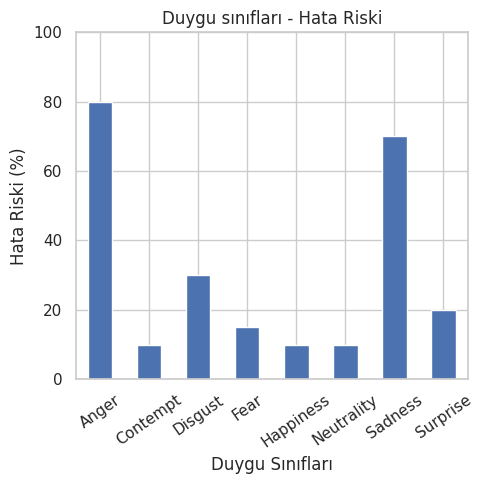

----------------------------------------------


<Figure size 500x500 with 0 Axes>

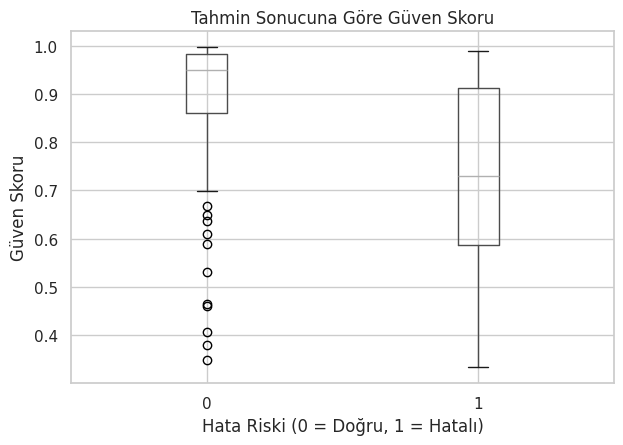

----------------------------------------------


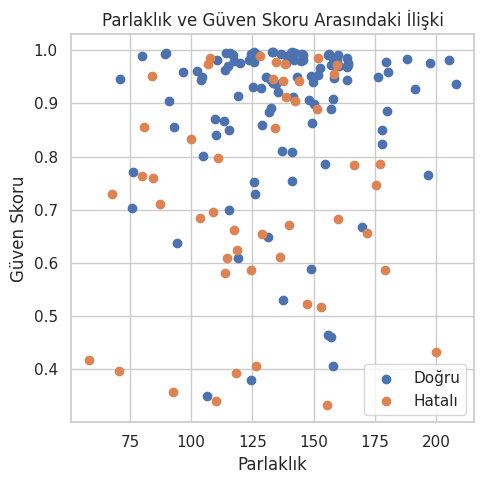

In [ ]:

import matplotlib.pyplot as plt

# Duygu sınıflarının isimleri
class_names = {
    0: "Anger",
    1: "Contempt",
    2: "Disgust",
    3: "Fear",
    4: "Happiness",
    5: "Neutrality",
    6: "Sadness",
    7: "Surprise"
}

# --------------------------------------------------
# Grafik 1: Sınıflara göre hata oranı
# --------------------------------------------------

class_error = (
    df.groupby("true_class")["error_risk"]
      .mean() * 100
)

class_error.index = [
    class_names[i] for i in class_error.index
]

plt.figure(figsize=(5, 5))
class_error.plot(kind="bar")

plt.title("Duygu sınıfları - Hata Riski")
plt.xlabel("Duygu Sınıfları")
plt.ylabel("Hata Riski (%)")
plt.xticks(rotation=35)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()
print("----------------------------------------------")
# --------------------------------------------------
# Grafik 2: Doğru ve yanlış tahminlerde
# güven skoru dağılımı
# --------------------------------------------------

plt.figure(figsize=(5, 5))

df.boxplot(
    column="confidence",
    by="error_risk"
)

plt.title("Tahmin Sonucuna Göre Güven Skoru")
plt.suptitle("")
plt.xlabel("Hata Riski (0 = Doğru, 1 = Hatalı)")
plt.ylabel("Güven Skoru")
plt.tight_layout()
plt.show()
print("----------------------------------------------")
# --------------------------------------------------
# Grafik 3: Parlaklık ve güven skoru ilişkisi
# --------------------------------------------------

plt.figure(figsize=(5, 5))

for risk, group in df.groupby("error_risk"):
    plt.scatter(
        group["brightness"],
        group["confidence"],
        label="Hatalı" if risk == 1 else "Doğru"
    )

plt.title("Parlaklık ve Güven Skoru Arasındaki İlişki")
plt.xlabel("Parlaklık")
plt.ylabel("Güven Skoru")
plt.legend()
plt.tight_layout()
plt.show()


**Decision Tree Classifier (İkinci Bölüm)**

In [ ]:
import pandas as pd
import numpy as np
from IPython.display import display, HTML

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    make_scorer
)

# --------------------------------------------------
# 1. Girdi özellikleri ve hedef değişken
# --------------------------------------------------

numeric_features = [
    "brightness",
    "blur",
    "contrast",
    "face_size",
    "confidence"
]

categorical_features = ["predicted_class"]

X = df[numeric_features + categorical_features]
y = df["error_risk"]

# --------------------------------------------------
# 2. Eğitim ve test ayrımı
# --------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

# Dağılım Tablosu
dist_df = pd.DataFrame({
    "Eğitim Kümesi": y_train.value_counts(),
    "Test Kümesi": y_test.value_counts()
})
dist_df.index = ["0 (Doğru)", "1 (Hatalı)"]

display(HTML("<h4>Veri Kümesi Sınıf Dağılımı</h4>"))
display(dist_df)

# --------------------------------------------------
# 3. Kategorik özelliği dönüştür
# --------------------------------------------------

preprocessor = ColumnTransformer(
    transformers=[
        (
            "class",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numeric",
            "passthrough",
            numeric_features
        )
    ]
)

# --------------------------------------------------
# 4. Decision Tree modeli
# --------------------------------------------------

decision_tree = Pipeline([
    ("preprocessor", preprocessor),
    (
        "classifier",
        DecisionTreeClassifier(
            max_depth=3,
            min_samples_leaf=5,
            class_weight="balanced",
            random_state=42
        )
    )
])

decision_tree.fit(X_train, y_train)

# --------------------------------------------------
# 5. Test tahminleri
# --------------------------------------------------

y_pred = decision_tree.predict(X_test)

# Baseline model
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

# Genel Metriklerin Karşılaştırma Tablosu
metrics_summary = pd.DataFrame({
    "Metrik": ["Accuracy", "Balanced Accuracy", "Precision", "Recall", "F1 Score"],
    "Decision Tree": [
        accuracy_score(y_test, y_pred),
        balanced_accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0)
    ],
    "Baseline Model": [
        accuracy_score(y_test, baseline_pred),
        balanced_accuracy_score(y_test, baseline_pred),
        precision_score(y_test, baseline_pred, zero_division=0),
        recall_score(y_test, baseline_pred, zero_division=0),
        f1_score(y_test, baseline_pred, zero_division=0)
    ]
}).round(3)

display(HTML("<h4>Model Performans Karşılaştırması (Test Seti)</h4>"))
display(metrics_summary)

# Sınıflandırma Raporu Tablosu
report_dict = classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Correct (Doğru)", "Incorrect (Hatalı)"],
    zero_division=0,
    output_dict=True
)
report_df = pd.DataFrame(report_dict).transpose().round(3)

display(HTML("<h4>Detaylı Sınıflandırma Raporu (Decision Tree)</h4>"))
display(report_df)

# Karmaşıklık Matrisi Tablosu
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
cm_df = pd.DataFrame(
    cm,
    index=["Gerçek Doğru (0)", "Gerçek Hatalı (1)"],
    columns=["Tahmin Doğru (0)", "Tahmin Hatalı (1)"]
)

display(HTML("<h4>Karmaşıklık Matrisi (Confusion Matrix)</h4>"))
display(cm_df)

# --------------------------------------------------
# 6. 5 katlı çapraz doğrulama
# --------------------------------------------------

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring_metrics = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "precision": make_scorer(
        precision_score,
        zero_division=0
    ),
    "recall": make_scorer(
        recall_score,
        zero_division=0
    ),
    "f1": make_scorer(
        f1_score,
        zero_division=0
    )
}

cv_results = cross_validate(
    decision_tree,
    X,
    y,
    cv=cv,
    scoring=scoring_metrics
)

cv_rows = []
for metric in scoring_metrics:
    scores = cv_results[f"test_{metric}"]
    cv_rows.append({
        "Metrik": metric.replace("_", " ").title(),
        "Ortalama Skor (Mean)": round(scores.mean(), 3),
        "Standart Sapma (Std)": round(scores.std(), 3)
    })

cv_df = pd.DataFrame(cv_rows)
display(HTML("<h4>5-Fold Cross Validation (Çapraz Doğrulama) Sonuçları</h4>"))
display(cv_df)

# --------------------------------------------------
# 7. Özellik önemleri
# --------------------------------------------------

fitted_preprocessor = decision_tree.named_steps["preprocessor"]
fitted_tree = decision_tree.named_steps["classifier"]
feature_names = fitted_preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Özellik (Feature)": feature_names,
    "Önem Derecesi (Importance)": fitted_tree.feature_importances_
}).sort_values(
    "Önem Derecesi (Importance)",
    ascending=False
).reset_index(drop=True)

display(HTML("<h4>Özellik Önem Dereceleri (Feature Importance)</h4>"))
display(importance_df.round(4))

,Eğitim Kümesi,Test Kümesi
0 (Doğru),83,28
1 (Hatalı),37,12


,Metrik,Decision Tree,Baseline Model
0,Accuracy,0.750,0.7
1,Balanced Accuracy,0.655,0.5
2,Precision,0.625,0.0
3,Recall,0.417,0.0
4,F1 Score,0.500,0.0


,precision,recall,f1-score,support
Correct (Doğru),0.781,0.893,0.833,28.00
Incorrect (Hatalı),0.625,0.417,0.500,12.00
accuracy,0.750,0.750,0.750,0.75
macro avg,0.703,0.655,0.667,40.00
weighted avg,0.734,0.750,0.733,40.00


,Tahmin Doğru (0),Tahmin Hatalı (1)
Gerçek Doğru (0),25,3
Gerçek Hatalı (1),7,5


,Metrik,Ortalama Skor (Mean),Standart Sapma (Std)
0,Accuracy,0.712,0.078
1,Balanced Accuracy,0.666,0.088
2,Precision,0.543,0.146
3,Recall,0.547,0.124
4,F1,0.539,0.121


,Özellik (Feature),Önem Derecesi (Importance)
0,numeric__confidence,0.7438
1,numeric__blur,0.1501
2,numeric__brightness,0.1061
3,class__predicted_class_1,0.0000
4,class__predicted_class_0,0.0000
5,class__predicted_class_4,0.0000
6,class__predicted_class_3,0.0000
7,class__predicted_class_2,0.0000
8,class__predicted_class_5,0.0000
9,class__predicted_class_7,0.0000


Decision Tree görselleştirme

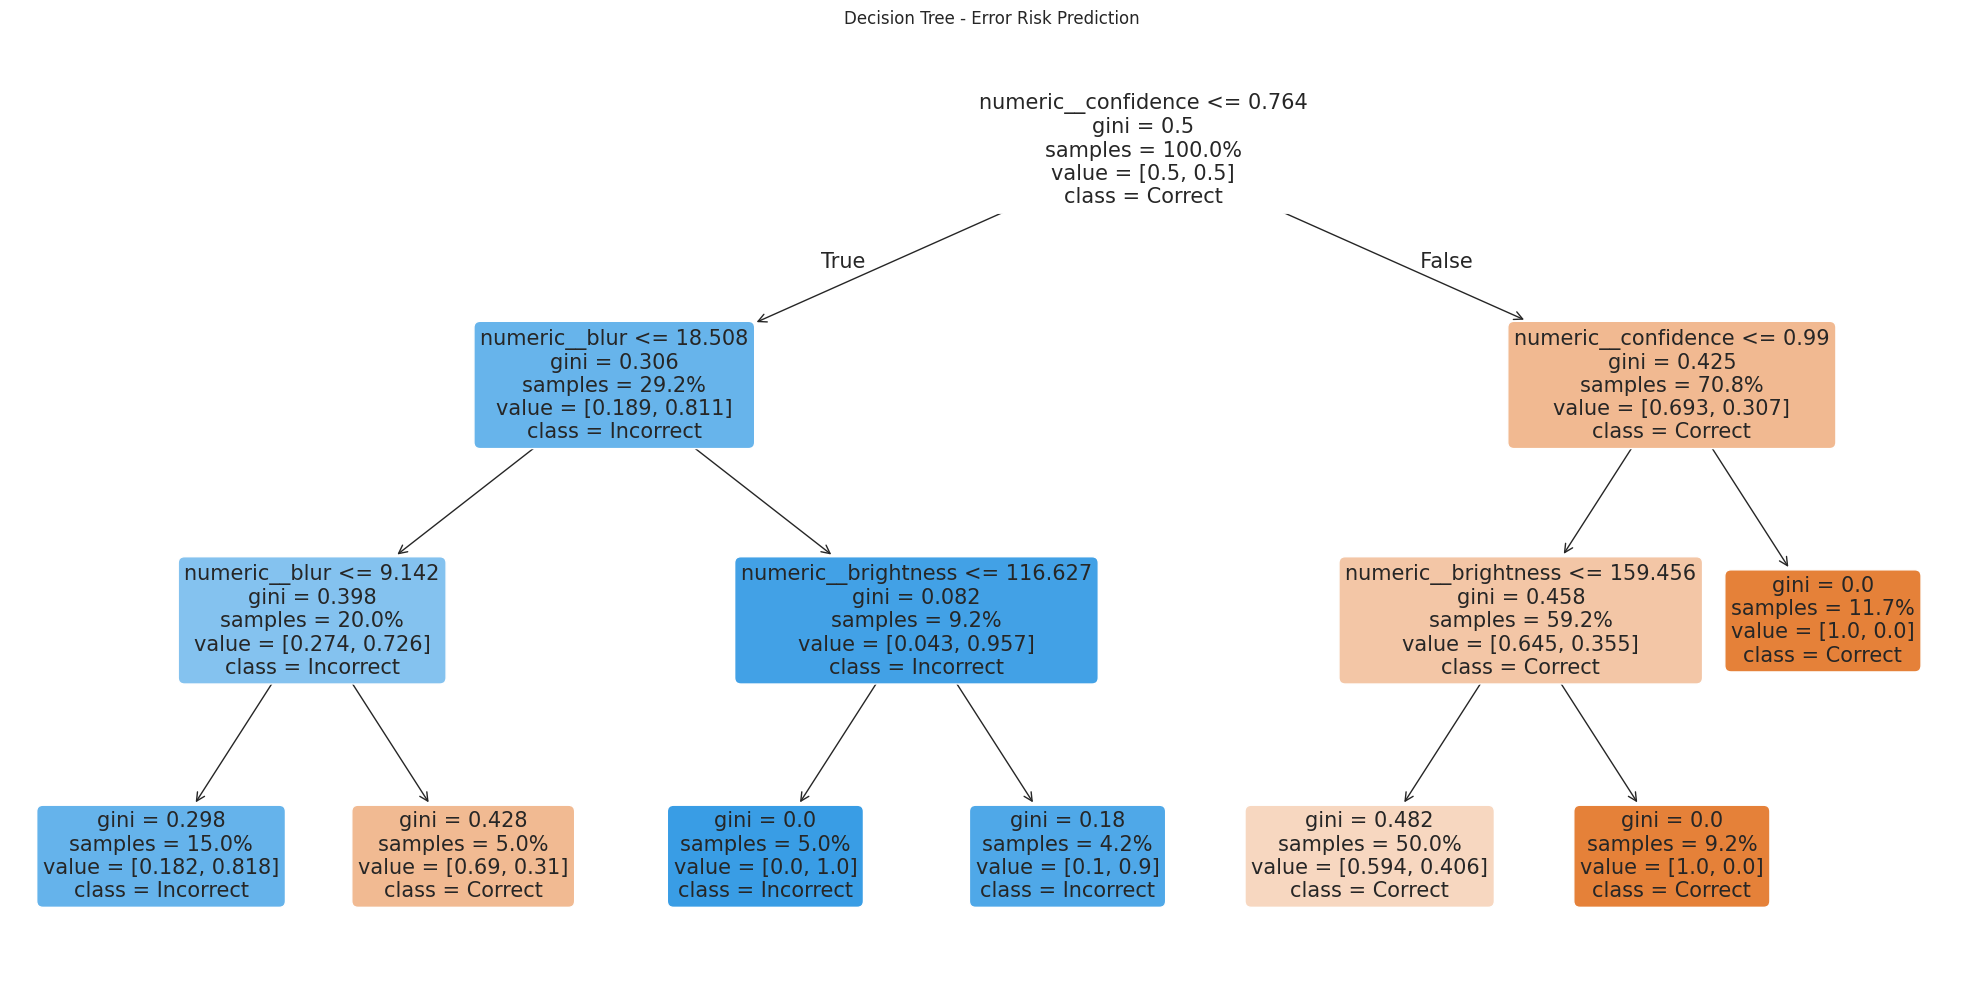

In [ ]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# decision_tree pipeline'ından eğitilmiş karar ağacını ve özellik adlarını alalım
try:
    fitted_preprocessor = decision_tree.named_steps["preprocessor"]
    fitted_tree = decision_tree.named_steps["classifier"]
    feature_names = fitted_preprocessor.get_feature_names_out()

    # Karar ağacını görselleştir
    plt.figure(figsize=(20, 10))
    plot_tree(
        fitted_tree,
        feature_names=feature_names,
        class_names=["Correct", "Incorrect"],
        filled=True,
        rounded=True,
        proportion=True,
        fontsize=15
    )
    plt.title("Decision Tree - Error Risk Prediction")
    plt.tight_layout()
    plt.show()
except NameError:
    print("Hata: 'decision_tree' modeli tanımlı değil. Lütfen önce 'WX6dAsodDxn-' hücresini çalıştırın.")

İkinci model ile YOLOv8'in hatalarını yakalama oranları

In [ ]:
# Test kümesindeki gerçek ve tahmin edilen hata risklerini birleştiriyoruz.
analysis_results = df.loc[X_test.index].copy()

analysis_results["actual_error_risk"] = y_test
analysis_results["predicted_error_risk"] = y_pred

# Dört sonucu ayırıyoruz.
true_negative = analysis_results[
    (analysis_results["actual_error_risk"] == 0) &
    (analysis_results["predicted_error_risk"] == 0)
]

false_positive = analysis_results[
    (analysis_results["actual_error_risk"] == 0) &
    (analysis_results["predicted_error_risk"] == 1)
]

false_negative = analysis_results[
    (analysis_results["actual_error_risk"] == 1) &
    (analysis_results["predicted_error_risk"] == 0)
]

true_positive = analysis_results[
    (analysis_results["actual_error_risk"] == 1) &
    (analysis_results["predicted_error_risk"] == 1)
]

print("=== YOLO HATALARINI YAKALAYANLAR (5) ===")
display(true_positive)
print("=============================================================")
print("=== YOLO HATALARINI KAÇIRANLAR (7) ===")
display(false_negative)
print("=============================================================")
print("=== YANLIŞ ALARMLAR (3) ===")
display(false_positive)
print("=============================================================")
print("=== DOĞRU DEĞERLENDİRİLENLER (25) ===")
display(true_negative)

=== YOLO HATALARINI YAKALAYANLAR (5) ===


,image,brightness,blur,contrast,face_size,confidence,predicted_class,true_class,error_risk,actual_error_risk,predicted_error_risk
15,anger10659.png,124.340601,6.739286,53.069837,0.997848,0.587024,2,0,1,1,1
122,sad067.png,140.095404,8.498146,58.939198,0.996891,0.670924,1,6,1,1,1
81,happy029.png,179.290717,6.679433,41.777791,0.998083,0.586212,2,4,1,1,1
136,sad10362.png,58.364656,6.842335,39.644242,0.999210,0.416786,1,6,1,1,1
130,sad10120.png,153.189672,5.584124,55.860512,0.998174,0.517853,5,6,1,1,1


=== YOLO HATALARINI KAÇIRANLAR (7) ===


,image,brightness,blur,contrast,face_size,confidence,predicted_class,true_class,error_risk,actual_error_risk,predicted_error_risk
150,surprise10114.png,151.553292,12.819930,57.036277,0.999220,0.890350,4,7,1,1,0
7,anger10414.png,137.669902,63.163320,49.505639,0.995982,0.942455,1,0,1,1,0
8,anger10440.png,133.363062,36.233248,60.327784,0.994119,0.945645,1,0,1,1,0
121,sad058.png,176.987982,6.473154,62.924113,0.997972,0.785505,3,6,1,1,0
5,anger1033.png,166.601523,8.153178,57.045658,0.997692,0.783800,5,0,1,1,0
135,sad10353.png,134.261719,7.869458,55.256241,0.998231,0.853363,5,6,1,1,0
9,anger10451.png,159.539381,79.010513,55.580754,0.998245,0.972737,2,0,1,1,0


=== YANLIŞ ALARMLAR (3) ===


,image,brightness,blur,contrast,face_size,confidence,predicted_class,true_class,error_risk,actual_error_risk,predicted_error_risk
12,anger10571.png,157.248625,108.066797,55.836014,0.996203,0.461552,0,0,0,0,1
10,anger1056.png,169.710160,8.380486,64.809418,0.998554,0.668068,0,0,0,0,1
79,fear11435.png,115.505859,5.650206,35.193834,0.993912,0.699598,3,3,0,0,1


=== DOĞRU DEĞERLENDİRİLENLER (25) ===


,image,brightness,blur,contrast,face_size,confidence,predicted_class,true_class,error_risk,actual_error_risk,predicted_error_risk
38,contempt13054.png,140.621253,19.125560,57.893496,0.999588,0.994014,1,1,0,0,0
39,contempt13178.png,187.945372,21.509003,45.313831,0.995730,0.983182,1,1,0,0,0
89,happy10036.png,125.486886,10.570596,49.961981,0.997887,0.753198,4,4,0,0,0
100,neutral018.png,159.624880,13.326500,46.513765,0.996216,0.982031,5,5,0,0,0
61,fear079.png,149.655891,122.568316,45.725655,0.996042,0.941232,3,3,0,0,0
118,neutral10736.png,160.145867,8.826214,67.422668,0.997657,0.991058,5,5,0,0,0
92,happy10067.png,142.205038,4.491843,40.977035,0.999019,0.995340,4,4,0,0,0
113,neutral10503.png,102.152563,6.662254,28.989951,0.997009,0.961866,5,5,0,0,0
103,neutral069.png,142.144511,7.017787,67.717145,0.999509,0.982421,5,5,0,0,0
104,neutral070.png,163.786810,13.003828,38.424331,0.997263,0.968729,5,5,0,0,0


İkinci model ile hata yakalama oranları genel değerlendirme

In [ ]:
import pandas as pd

groups = {
    "Yakalanan hatalar": true_positive,
    "Kaçırılan hatalar": false_negative,
    "Yanlış alarmlar": false_positive,
    "Doğru değerlendirilenler": true_negative
}

summary = []

for name, group in groups.items():
    summary.append({
        "Grup": name,
        "Örnek sayısı": len(group),
        "Ortalama confidence": group["confidence"].mean(),
        "Ortalama blur": group["blur"].mean(),
        "Ortalama brightness": group["brightness"].mean(),
        "Ortalama contrast": group["contrast"].mean()
    })

summary_df = pd.DataFrame(summary)

display(
    summary_df.style.format({
        "Ortalama confidence": "{:.3f}",
        "Ortalama blur": "{:.2f}",
        "Ortalama brightness": "{:.2f}",
        "Ortalama contrast": "{:.2f}"
    })
)

,Grup,Örnek sayısı,Ortalama confidence,Ortalama blur,Ortalama brightness,Ortalama contrast
0,Yakalanan hatalar,5,0.556,6.87,131.06,49.86
1,Kaçırılan hatalar,7,0.882,30.53,151.43,56.81
2,Yanlış alarmlar,3,0.610,40.70,147.49,51.95
3,Doğru değerlendirilenler,25,0.955,18.97,150.67,49.59


Sınıf bazlı kaçırılan hata oranları

In [ ]:
class_names = {
    0: "anger",
    1: "contempt",
    2: "disgust",
    3: "fear",
    4: "happiness",
    5: "neutrality",
    6: "sadness",
    7: "surprise"
}

missed = false_negative.copy()

missed["Gerçek duygu"] = missed["true_class"].map(class_names)
missed["YOLO tahmini"] = missed["predicted_class"].map(class_names)

print("=== KAÇIRILAN HATALARIN SINIF DAĞILIMI ===")

display(
    missed.groupby(
        ["Gerçek duygu", "YOLO tahmini"]
    ).size().reset_index(name="Örnek sayısı")
)

=== KAÇIRILAN HATALARIN SINIF DAĞILIMI ===


,Gerçek duygu,YOLO tahmini,Örnek sayısı
0,anger,contempt,2
1,anger,disgust,1
2,anger,neutrality,1
3,sadness,fear,1
4,sadness,neutrality,1
5,surprise,happiness,1


**Yeni görüntülerde hata riski tahmini
(YOLOV8 -> Görüntü Özellikleri + YOLO çıktısı -> Decision Tree (İkinci Model))**

In [ ]:
from ultralytics import YOLO
import joblib

# YOLO modelimizi yükleyelim
yolo_model = YOLO("/content/emotions56/yolov8n-emo.pt")

# Eğittiğimiz karar ağacını kaydedip yükleyeceğiz.
# Birazdan fitted_tree nesnesini kaydedeceğiz.

class_names = {
    0: "anger",
    1: "contempt",
    2: "disgust",
    3: "fear",
    4: "happiness",
    5: "neutrality",
    6: "sadness",
    7: "surprise"
}

print("YOLO modeli hazır!")

YOLO modeli hazır!


Karar Ağacı Modeli

In [ ]:
import joblib

joblib.dump(
    decision_tree,
    "/content/error_risk_model.joblib"
)

print("Hata riski modeli kaydedildi!")

Hata riski modeli kaydedildi!


Tahmin Fonksiyonu

In [ ]:
import cv2
import numpy as np
import pandas as pd
from google.colab import files
from IPython.display import display

# Kaydettiğimiz ikinci modeli yükle
error_model = joblib.load("/content/error_risk_model.joblib")

def predict_emotion_and_risk(image_path):

    # Görüntüyü oku
    image = cv2.imread(image_path)

    if image is None:
        raise ValueError("Görüntü okunamadı!")

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Görüntü özelliklerini hesapla
    brightness = float(np.mean(gray))
    contrast = float(np.std(gray))
    blur = float(cv2.Laplacian(gray, cv2.CV_64F).var())

    height, width = image.shape[:2]

    # YOLO tahmini
    results = yolo_model.predict(
        source=image,
        conf=0.001,
        iou=0.7,
        verbose=False
    )

    boxes = results[0].boxes

    # En yüksek confidence değerine sahip kutuyu al
    if boxes is not None and len(boxes) > 0:

        best_index = int(boxes.conf.argmax())

        confidence = float(boxes.conf[best_index])
        predicted_class = int(boxes.cls[best_index])

        x1, y1, x2, y2 = boxes.xyxy[best_index].cpu().numpy()

        face_size = float(
            ((x2 - x1) * (y2 - y1)) / (width * height)
        )

    else:
        print("YOLO görüntüde yüz tespit edemedi.")
        return

    # İkinci modelin beklediği özellikler
    features = pd.DataFrame([{
        "brightness": brightness,
        "blur": blur,
        "contrast": contrast,
        "face_size": face_size,
        "confidence": confidence,
        "predicted_class": predicted_class
    }])

    # Hata riski tahmini
    risk_prediction = int(error_model.predict(features)[0])

    # Tahmin olasılıkları
    probabilities = error_model.predict_proba(features)[0]
    risk_probability = float(probabilities[1])

    # Sonuçları göster
    print("\n========== TAHMİN SONUCU ==========")
    print("YOLO duygu tahmini:", class_names[predicted_class])
    print("YOLO confidence:", round(confidence, 4))

    print("\nGörüntü özellikleri:")
    print("Brightness:", round(brightness, 2))
    print("Blur:", round(blur, 2))
    print("Contrast:", round(contrast, 2))
    print("Face size:", round(face_size, 4))

    print("\nİKİNCİ MODEL SONUCU:")

    if risk_prediction == 1:
        print("Hata riski: YÜKSEK")
    else:
        print("Hata riski: DÜŞÜK")

    print("Tahmin edilen hata olasılığı:",
          f"%{risk_probability * 100:.2f}")

    display(features)

Tahmin Fonksiyonuna Sonuç Kaydı Ekleme Fonksiyonu

In [ ]:
import os
import re

def get_prediction_details(image_path, predicted_class, confidence, brightness, blur, contrast, face_size, risk_prediction, risk_probability, class_names):
    # Dosya adından gerçek duygu sınıfını bul
    filename = os.path.basename(image_path)

    prefix = re.match(r"^[a-z]+", filename.lower()).group()

    true_class_map = {
        "anger": "anger",
        "contempt": "contempt",
        "disgust": "disgust",
        "fear": "fear",
        "happy": "happiness",
        "neutral": "neutrality",
        "sad": "sadness",
        "surprise": "surprise"
    }

    true_emotion = true_class_map[prefix]
    predicted_emotion = class_names[predicted_class]

    return {
        "image": filename,
        "true_emotion": true_emotion,
        "yolo_prediction": predicted_emotion,
        "confidence": confidence,
        "brightness": brightness,
        "blur": blur,
        "contrast": contrast,
        "face_size": face_size,
        "yolo_correct": int(predicted_emotion == true_emotion),
        "risk_prediction": risk_prediction,
        "risk_probability": risk_probability
    }

Tahmin Fonksiyonu işlemi (her duygu için ilk 3 görsel)

In [ ]:
import glob
import os
import re
import cv2
import numpy as np
import pandas as pd
from IPython.display import display

image_folder = "/content/emotions56_test/test/images"

emotion_names = [
    "anger",
    "contempt",
    "disgust",
    "fear",
    "happy",
    "neutral",
    "sad",
    "surprise"
]

# Sonuçları toplamak için boş bir liste
table_records = []

for emotion in emotion_names:
    files_list = glob.glob(
        os.path.join(image_folder, f"{emotion}*.png")
    )

    # Dosya numarasına göre sırala
    files_list = sorted(
        files_list,
        key=lambda x: int(
            re.search(r'\d+', os.path.basename(x)).group()
        )
    )

    # Her duygu sınıfından ilk 3 görüntüyü seç
    selected_images = files_list[:3]

    for image_path in selected_images:
        # Görüntüyü oku ve özellikleri hesapla
        image = cv2.imread(image_path)
        if image is None:
            continue

        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        brightness = float(np.mean(gray))
        contrast = float(np.std(gray))
        blur = float(cv2.Laplacian(gray, cv2.CV_64F).var())
        height, width = image.shape[:2]

        # YOLO tahmini
        results = yolo_model.predict(
            source=image,
            conf=0.001,
            iou=0.7,
            verbose=False
        )
        boxes = results[0].boxes

        if boxes is not None and len(boxes) > 0:
            best_index = int(boxes.conf.argmax())
            confidence = float(boxes.conf[best_index])
            predicted_class = int(boxes.cls[best_index])
            x1, y1, x2, y2 = boxes.xyxy[best_index].cpu().numpy()
            face_size = float(((x2 - x1) * (y2 - y1)) / (width * height))
        else:
            predicted_class = -1
            confidence = 0.0
            face_size = 0.0

        # İkinci model girdileri
        features = pd.DataFrame([{
            "brightness": brightness,
            "blur": blur,
            "contrast": contrast,
            "face_size": face_size,
            "confidence": confidence,
            "predicted_class": predicted_class
        }])

        # Hata riski tahmini
        risk_prediction = int(error_model.predict(features)[0])
        probabilities = error_model.predict_proba(features)[0]
        risk_probability = float(probabilities[1])

        # Detayları al ve listeye ekle
        if predicted_class != -1:
            # get_prediction_details fonksiyonunun daha önce tanımlanmış olması gerekir.
            try:
                detail = get_prediction_details(
                    image_path=image_path,
                    predicted_class=predicted_class,
                    confidence=confidence,
                    brightness=brightness,
                    blur=blur,
                    contrast=contrast,
                    face_size=face_size,
                    risk_prediction=risk_prediction,
                    risk_probability=risk_probability,
                    class_names=class_names
                )
                table_records.append(detail)
            except NameError:
                print("Hata: 'get_prediction_details' fonksiyonu bulunamadı. Lütfen üstteki tanım hücrelerini sırayla çalıştırın.")
                break

# DataFrame oluşturma ve şık biçimlendirme
if len(table_records) > 0:
    df_preview = pd.DataFrame(table_records)
    display(df_preview.style.format({
        "confidence": "{:.4f}",
        "brightness": "{:.2f}",
        "blur": "{:.2f}",
        "contrast": "{:.2f}",
        "face_size": "{:.4f}",
        "risk_probability": "%{:.2f}"
    }).set_table_styles([
        {'selector': 'th', 'props': [('background-color', '#2E4053'), ('color', 'white'), ('font-weight', 'bold')]}
    ]))

,image,true_emotion,yolo_prediction,confidence,brightness,blur,contrast,face_size,yolo_correct,risk_prediction,risk_probability
0,anger001.png,anger,surprise,0.6617,117.42,7.81,45.75,0.9972,0,1,%0.82
1,anger003.png,anger,anger,0.9909,145.62,528.09,62.66,0.9972,1,0,%0.00
2,anger1013.png,anger,disgust,0.7606,84.43,7.31,56.01,0.9950,0,1,%0.82
3,contempt001.png,contempt,contempt,0.7711,76.23,20.01,57.54,0.9978,1,0,%0.41
4,contempt1032.png,contempt,neutrality,0.7640,79.81,24.38,36.72,0.9952,0,1,%1.00
5,contempt10182.png,contempt,contempt,0.8548,92.92,24.97,42.46,0.9966,1,0,%0.41
6,disgust010.png,disgust,disgust,0.8864,180.15,42.23,44.01,0.9983,1,0,%0.00
7,disgust032.png,disgust,disgust,0.9852,163.66,8.41,38.64,0.9989,1,0,%0.00
8,disgust044.png,disgust,disgust,0.8624,149.18,28.15,50.84,0.9999,1,0,%0.41
9,fear013.png,fear,fear,0.8705,109.54,14.14,44.57,0.9981,1,0,%0.41


YOLOv8 ve Decision Tree hata riski hesaplama

In [ ]:
import pandas as pd
from IPython.display import display

records = []

for emotion in emotion_names:

    files_list = glob.glob(
        os.path.join(image_folder, f"{emotion}*.png")
    )

    files_list = sorted(
        files_list,
        key=lambda x: int(
            re.search(r'\d+', os.path.basename(x)).group()
        )
    )

    for image_path in files_list[:3]:

        result = predict_emotion_and_risk(image_path)

        if result is not None:
            records.append(result)

# Sonuçları DataFrame'e aktar
df_results = pd.DataFrame(records)

# CSV olarak kaydet
df_results.to_csv(
    "/content/24_goruntu_analiz_sonuclari.csv",
    index=False
)

print("Toplam analiz edilen görüntü:", len(df_results))

display(df_results)


========== TAHMİN SONUCU ==========
YOLO duygu tahmini: surprise
YOLO confidence: 0.6617

Görüntü özellikleri:
Brightness: 117.42
Blur: 7.81
Contrast: 45.75
Face size: 0.9972

İKİNCİ MODEL SONUCU:
Hata riski: YÜKSEK
Tahmin edilen hata olasılığı: %81.77


,brightness,blur,contrast,face_size,confidence,predicted_class
0,117.42337,7.808967,45.746452,0.997223,0.661676,7



========== TAHMİN SONUCU ==========
YOLO duygu tahmini: anger
YOLO confidence: 0.9909

Görüntü özellikleri:
Brightness: 145.62
Blur: 528.09
Contrast: 62.66
Face size: 0.9972

İKİNCİ MODEL SONUCU:
Hata riski: DÜŞÜK
Tahmin edilen hata olasılığı: %0.00


,brightness,blur,contrast,face_size,confidence,predicted_class
0,145.616689,528.093989,62.656864,0.997204,0.990852,0



========== TAHMİN SONUCU ==========
YOLO duygu tahmini: disgust
YOLO confidence: 0.7606

Görüntü özellikleri:
Brightness: 84.43
Blur: 7.31
Contrast: 56.01
Face size: 0.995

İKİNCİ MODEL SONUCU:
Hata riski: YÜKSEK
Tahmin edilen hata olasılığı: %81.77


,brightness,blur,contrast,face_size,confidence,predicted_class
0,84.428213,7.309006,56.012843,0.995024,0.76058,2


... (40 outputs left out)


========== TAHMİN SONUCU ==========
YOLO duygu tahmini: surprise
YOLO confidence: 0.4066

Görüntü özellikleri:
Brightness: 158.09
Blur: 17.77
Contrast: 44.92
Face size: 0.997

İKİNCİ MODEL SONUCU:
Hata riski: DÜŞÜK
Tahmin edilen hata olasılığı: %30.97


,brightness,blur,contrast,face_size,confidence,predicted_class
0,158.092514,17.773604,44.91723,0.996996,0.406617,7


Toplam analiz edilen görüntü: 0


""


Genel Performans Analizi

Metrik,Değer
Toplam Görüntü,24
YOLO Doğru Tahmin,15
YOLO Yanlış Tahmin,9
YOLO Doğruluk Oranı,%62.50


,Tahmin Edilen Doğru (0),Tahmin Edilen Yanlış (1)
Gerçek YOLO Doğru (0),15,0
Gerçek YOLO Yanlış (1),2,7


,precision,recall,f1-score,support
YOLO Doğru,0.882000,1.000000,0.938000,15.000000
YOLO Yanlış,1.000000,0.778000,0.875000,9.000000
accuracy,0.917000,0.917000,0.917000,0.917000
macro avg,0.941000,0.889000,0.906000,24.000000
weighted avg,0.926000,0.917000,0.914000,24.000000


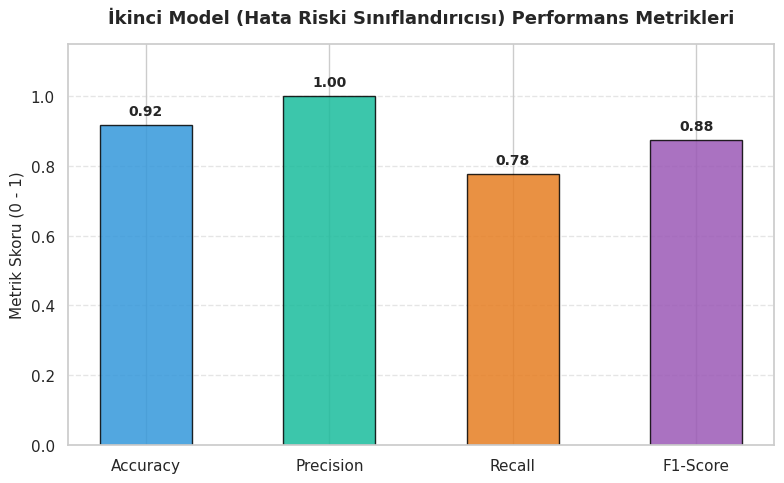

In [ ]:
import os
import glob
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score

# 1. df_results verisini get_prediction_details kullanarak yeniden oluşturalım
records = []

for emotion in emotion_names:
    files_list = glob.glob(os.path.join(image_folder, f"{emotion}*.png"))
    files_list = sorted(files_list, key=lambda x: int(re.search(r'\d+', os.path.basename(x)).group()))

    for image_path in files_list[:3]:
        image = cv2.imread(image_path)
        if image is None:
            continue

        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        brightness = float(np.mean(gray))
        contrast = float(np.std(gray))
        blur = float(cv2.Laplacian(gray, cv2.CV_64F).var())
        height, width = image.shape[:2]

        results = yolo_model.predict(source=image, conf=0.001, iou=0.7, verbose=False)
        boxes = results[0].boxes

        if boxes is not None and len(boxes) > 0:
            best_index = int(boxes.conf.argmax())
            confidence = float(boxes.conf[best_index])
            predicted_class = int(boxes.cls[best_index])
            x1, y1, x2, y2 = boxes.xyxy[best_index].cpu().numpy()
            face_size = float(((x2 - x1) * (y2 - y1)) / (width * height))
        else:
            predicted_class = -1
            confidence = 0.0
            face_size = 0.0

        # İkinci model (hata riski tahmini)
        features = pd.DataFrame([{
            "brightness": brightness,
            "blur": blur,
            "contrast": contrast,
            "face_size": face_size,
            "confidence": confidence,
            "predicted_class": predicted_class
        }])

        risk_prediction = int(error_model.predict(features)[0])
        probabilities = error_model.predict_proba(features)[0]
        risk_probability = float(probabilities[1])

        # get_prediction_details fonksiyonu ile detayları alıp ekleyelim
        if predicted_class != -1:
            detail = get_prediction_details(
                image_path=image_path,
                predicted_class=predicted_class,
                confidence=confidence,
                brightness=brightness,
                blur=blur,
                contrast=contrast,
                face_size=face_size,
                risk_prediction=risk_prediction,
                risk_probability=risk_probability,
                class_names=class_names
            )
            records.append(detail)

df_results = pd.DataFrame(records)

# 2. Performans Analiz Raporunun Tablolaştırılması
actual_errors = 1 - df_results["yolo_correct"]
predicted_errors = df_results["risk_prediction"]

# YOLO Genel Metrikleri
yolo_accuracy = df_results["yolo_correct"].mean()
yolo_summary_df = pd.DataFrame({
    "Metrik": ["Toplam Görüntü", "YOLO Doğru Tahmin", "YOLO Yanlış Tahmin", "YOLO Doğruluk Oranı"],
    "Değer": [
        len(df_results),
        df_results["yolo_correct"].sum(),
        actual_errors.sum(),
        f"%{yolo_accuracy * 100:.2f}"
    ]
})

display(HTML("<h4 style='color: #2E4053;'>1. YOLOv8 Model Performansı</h4>"))
display(yolo_summary_df.style.set_table_styles([
    {'selector': 'th', 'props': [('background-color', '#2E4053'), ('color', 'white'), ('font-weight', 'bold')]}
]).hide(axis='index'))

# İkinci Model Karmaşıklık Matrisi Tablosu
cm = confusion_matrix(actual_errors, predicted_errors, labels=[0, 1])
cm_df = pd.DataFrame(
    cm,
    index=["Gerçek YOLO Doğru (0)", "Gerçek YOLO Yanlış (1)"],
    columns=["Tahmin Edilen Doğru (0)", "Tahmin Edilen Yanlış (1)"]
)

display(HTML("<h4 style='color: #196F3D;'>2. İkinci Model Karmaşıklık Matrisi (Confusion Matrix)</h4>"))
display(cm_df.style.set_table_styles([
    {'selector': 'th', 'props': [('background-color', '#196F3D'), ('color', 'white'), ('font-weight', 'bold')]}
]))

# Sınıflandırma Raporunun DataFrame'e Dönüştürülmesi
report_dict = classification_report(
    actual_errors,
    predicted_errors,
    labels=[0, 1],
    target_names=["YOLO Doğru", "YOLO Yanlış"],
    zero_division=0,
    output_dict=True
)
report_df = pd.DataFrame(report_dict).transpose().round(3)

display(HTML("<h4 style='color: #7D6608;'>3. İkinci Model Detaylı Sınıflandırma Raporu</h4>"))
display(report_df.style.set_table_styles([
    {'selector': 'th', 'props': [('background-color', '#7D6608'), ('color', 'white'), ('font-weight', 'bold')]}
]))

# 3. Grafiksel Görselleştirme (Bar Plot)
metrics_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
metrics_values = [
    accuracy_score(actual_errors, predicted_errors),
    precision_score(actual_errors, predicted_errors, zero_division=0),
    recall_score(actual_errors, predicted_errors, zero_division=0),
    f1_score(actual_errors, predicted_errors, zero_division=0)
]

plt.figure(figsize=(8, 5))
colors = ['#3498DB', '#1ABC9C', '#E67E22', '#9B59B6']
bars = plt.bar(metrics_names, metrics_values, color=colors, width=0.5, edgecolor='black', alpha=0.85)

plt.title("İkinci Model (Hata Riski Sınıflandırıcısı) Performans Metrikleri", fontsize=13, fontweight='bold', pad=15)
plt.ylabel("Metrik Skoru (0 - 1)", fontsize=11)
plt.ylim(0, 1.15)
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Değer etiketlerini çubukların üzerine ekleyelim
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2.0,
        height + 0.02,
        f"{height:.2f}",
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

Duygu Sınıflarına Göre Karşılaştırma

In [ ]:
class_analysis = df_results.groupby("true_emotion").agg(
    image_count=("image", "count"),
    yolo_correct=("yolo_correct", "sum"),
    yolo_errors=("yolo_correct", lambda x: (1 - x).sum()),
    high_risk=("risk_prediction", "sum"),
    average_confidence=("confidence", "mean"),
    average_risk=("risk_probability", "mean")
).reset_index()

class_analysis["yolo_accuracy"] = (
    class_analysis["yolo_correct"]
    / class_analysis["image_count"] * 100
)

class_analysis["high_risk_rate"] = (
    class_analysis["high_risk"]
    / class_analysis["image_count"] * 100
)

display(class_analysis.round(2))

,true_emotion,image_count,yolo_correct,yolo_errors,high_risk,average_confidence,average_risk,yolo_accuracy,high_risk_rate
0,anger,3,1,2,2,0.80,0.55,33.33,66.67
1,contempt,3,2,1,1,0.80,0.60,66.67,33.33
2,disgust,3,3,0,0,0.91,0.14,100.00,0.00
3,fear,3,3,0,0,0.92,0.41,100.00,0.00
4,happiness,3,2,1,1,0.86,0.27,66.67,33.33
5,neutrality,3,3,0,0,0.86,0.10,100.00,0.00
6,sadness,3,0,3,2,0.62,0.61,0.00,66.67
7,surprise,3,1,2,1,0.67,0.51,33.33,33.33


Görselleştirme

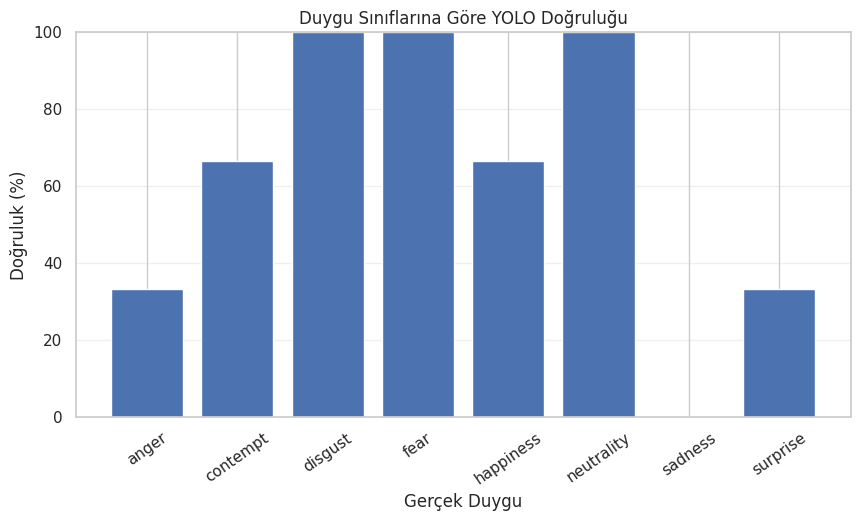

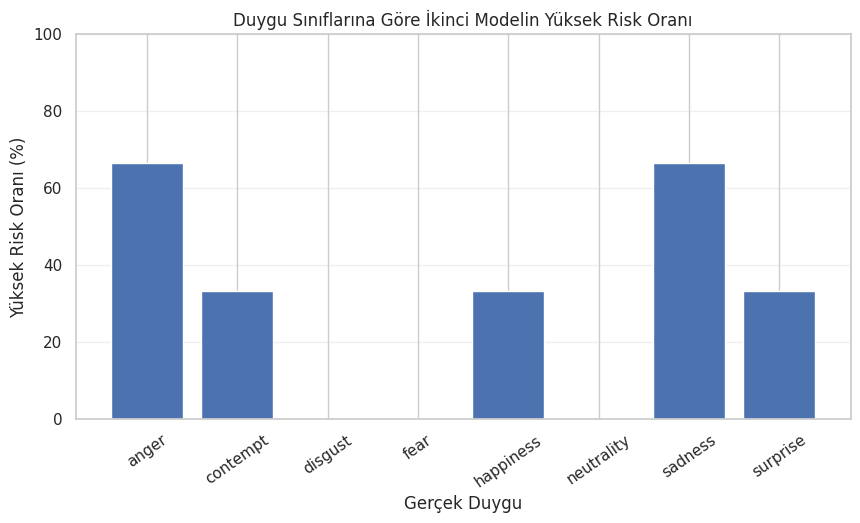

In [ ]:
import matplotlib.pyplot as plt

# YOLO doğruluk grafiği
plt.figure(figsize=(10, 5))

plt.bar(
    class_analysis["true_emotion"],
    class_analysis["yolo_accuracy"]
)

plt.title("Duygu Sınıflarına Göre YOLO Doğruluğu")
plt.xlabel("Gerçek Duygu")
plt.ylabel("Doğruluk (%)")
plt.ylim(0, 100)
plt.xticks(rotation=35)
plt.grid(axis="y", alpha=0.3)
plt.show()


# İkinci modelin yüksek risk oranı
plt.figure(figsize=(10, 5))

plt.bar(
    class_analysis["true_emotion"],
    class_analysis["high_risk_rate"]
)

plt.title("Duygu Sınıflarına Göre İkinci Modelin Yüksek Risk Oranı")
plt.xlabel("Gerçek Duygu")
plt.ylabel("Yüksek Risk Oranı (%)")
plt.ylim(0, 100)
plt.xticks(rotation=35)
plt.grid(axis="y", alpha=0.3)
plt.show()

160 görüntü verisinin tamamamı için çarpraz doğrulama tahminleri

Toplam görüntü: 160
Gerçek YOLO hatası: 49
Gerçek YOLO doğrusu: 111

ÇAPRAZ DOĞRULAMA SONUÇLARI
Accuracy: 0.713
Balanced accuracy: 0.667

SINIFLANDIRMA RAPORU
              precision    recall  f1-score   support

  YOLO doğru       0.80      0.78      0.79       111
 YOLO yanlış       0.53      0.55      0.54        49

    accuracy                           0.71       160
   macro avg       0.66      0.67      0.67       160
weighted avg       0.72      0.71      0.71       160



,image,brightness,blur,contrast,face_size,confidence,predicted_class,true_class,error_risk,actual_error,predicted_error,predicted_risk_probability
0,anger001.png,117.423370,7.808967,45.746452,0.997223,0.661676,7,0,1,1,0,0.363265
1,anger003.png,145.616689,528.093989,62.656864,0.997204,0.990852,0,0,0,0,0,0.000000
2,anger10015.png,87.396584,109.929386,59.634450,0.995763,0.711389,1,0,1,1,0,0.000000
3,anger1013.png,84.428213,7.309006,56.012843,0.995024,0.760580,2,0,1,1,0,0.461078
4,anger10283.png,118.818977,55.443874,69.040938,0.999298,0.624026,3,0,1,1,1,0.715447


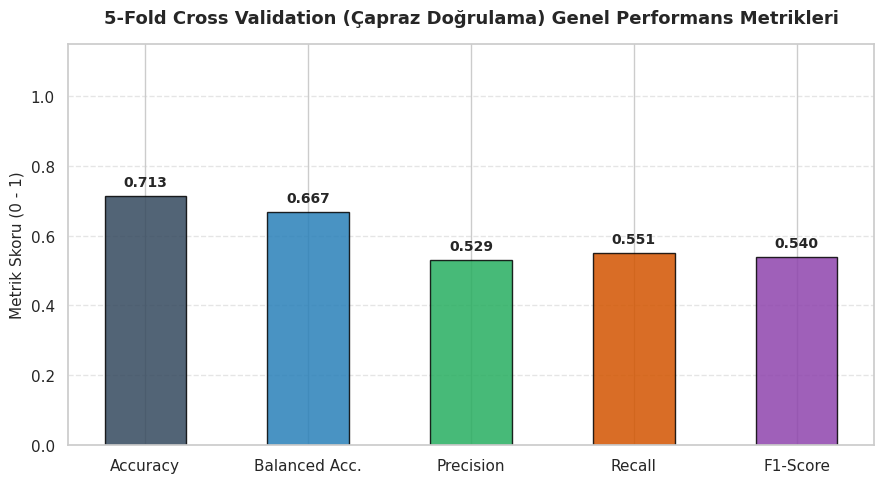

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# 5 katlı çapraz doğrulama
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Her görüntü için, onu eğitimde görmemiş modelden tahmin al
oof_predictions = cross_val_predict(
    decision_tree,
    X,
    y,
    cv=cv,
    method="predict"
)

# Hata sınıfına ait tahmin olasılıkları
oof_probabilities = cross_val_predict(
    decision_tree,
    X,
    y,
    cv=cv,
    method="predict_proba"
)

# İkinci modelin sınıf sırasını kontrol et
error_class_index = list(decision_tree.classes_).index(1)

# Sonuç tablosu
analysis_df = df.copy()

analysis_df["actual_error"] = y.to_numpy()
analysis_df["predicted_error"] = oof_predictions
analysis_df["predicted_risk_probability"] = (
    oof_probabilities[:, error_class_index]
)

print("Toplam görüntü:", len(analysis_df))
print("Gerçek YOLO hatası:", analysis_df["actual_error"].sum())
print("Gerçek YOLO doğrusu:", (analysis_df["actual_error"] == 0).sum())

print("\nÇAPRAZ DOĞRULAMA SONUÇLARI")

acc = accuracy_score(y, oof_predictions)
bal_acc = balanced_accuracy_score(y, oof_predictions)
prec = precision_score(y, oof_predictions, zero_division=0)
rec = recall_score(y, oof_predictions, zero_division=0)
f1 = f1_score(y, oof_predictions, zero_division=0)

print(f"Accuracy: {acc:.3f}")
print(f"Balanced accuracy: {bal_acc:.3f}")

print("\nSINIFLANDIRMA RAPORU")
print(
    classification_report(
        y,
        oof_predictions,
        target_names=["YOLO doğru", "YOLO yanlış"],
        zero_division=0
    )
)

display(analysis_df.head())

# Sonuçları kaydet
analysis_df.to_csv(
    "/content/160_goruntu_capraz_dogrulama_sonuclari.csv",
    index=False
)

# --- GRAFİKSEL GÖSTERİM BÖLÜMÜ ---
metrics_names = ['Accuracy', 'Balanced Acc.', 'Precision', 'Recall', 'F1-Score']
metrics_values = [acc, bal_acc, prec, rec, f1]

plt.figure(figsize=(9, 5))
colors = ['#34495E', '#2980B9', '#27AE60', '#D35400', '#8E44AD']
bars = plt.bar(metrics_names, metrics_values, color=colors, width=0.5, edgecolor='black', alpha=0.85)

plt.title("5-Fold Cross Validation (Çapraz Doğrulama) Genel Performans Metrikleri", fontsize=13, fontweight='bold', pad=15)
plt.ylabel("Metrik Skoru (0 - 1)", fontsize=11)
plt.ylim(0, 1.15)
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Değer etiketlerini sütunların üzerine yazdıralım
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2.0,
        height + 0.02,
        f"{height:.3f}",
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

Grafik 1- İkinci modelin hata tespit performansı

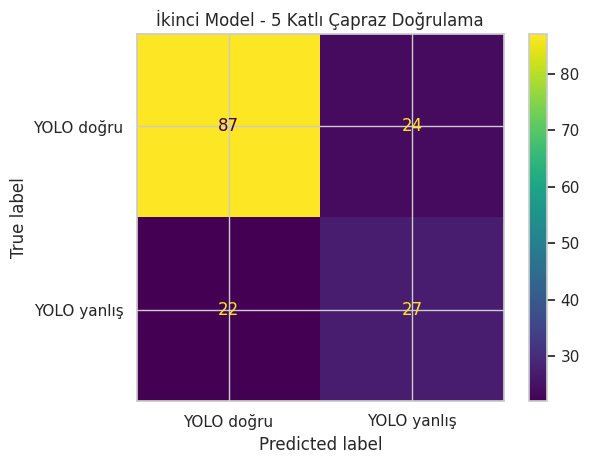

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(
    analysis_df["actual_error"],
    analysis_df["predicted_error"],
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["YOLO doğru", "YOLO yanlış"]
)

disp.plot(values_format="d")

plt.title("İkinci Model - 5 Katlı Çapraz Doğrulama")
plt.tight_layout()
plt.show()

Grafik 2- Duygu sınıflarına göre YOLO hata oranı

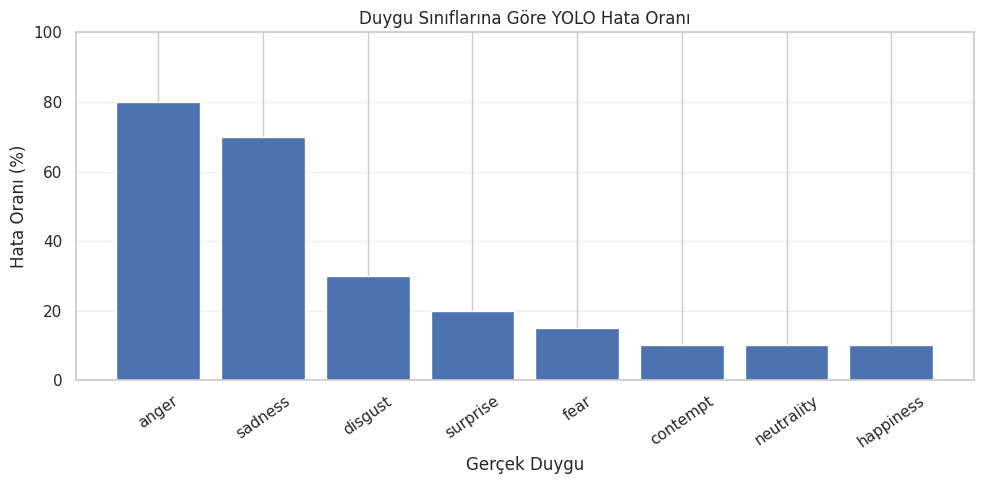

In [ ]:
class_names = {
    0: "anger",
    1: "contempt",
    2: "disgust",
    3: "fear",
    4: "happiness",
    5: "neutrality",
    6: "sadness",
    7: "surprise"
}

analysis_df["emotion"] = (
    analysis_df["true_class"].map(class_names)
)

class_errors = (
    analysis_df.groupby("emotion")["actual_error"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))

plt.bar(class_errors.index, class_errors.values)

plt.title("Duygu Sınıflarına Göre YOLO Hata Oranı")
plt.xlabel("Gerçek Duygu")
plt.ylabel("Hata Oranı (%)")
plt.ylim(0, 100)
plt.xticks(rotation=35)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

Grafik 3- Confidence ve gerçek hata ilişkisi

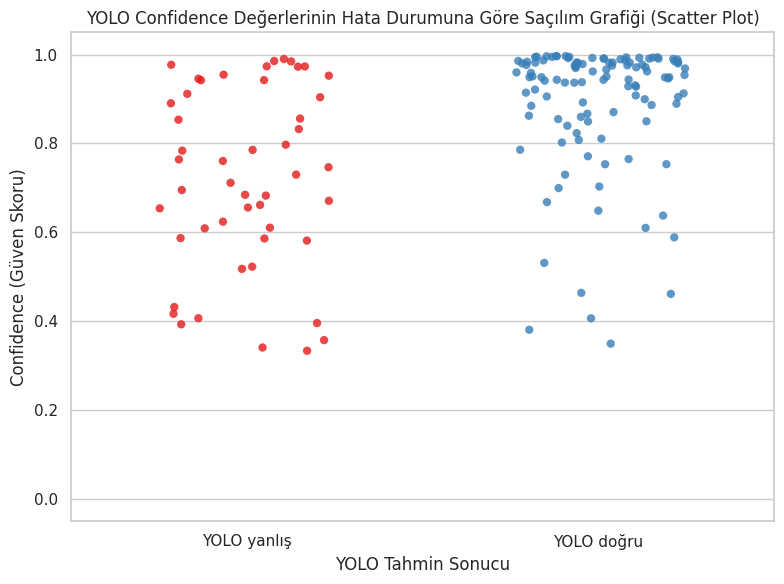

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.set_theme(style="whitegrid")

# Gerçek durum isimlerini eşleştirme
analysis_df["YOLO Durumu"] = analysis_df["actual_error"].map({0: "YOLO doğru", 1: "YOLO yanlış"})

# Saçılım grafiği (Stripplot ile her veri noktasını net göstermek ve jitter eklemek için)
sns.stripplot(
    data=analysis_df,
    x="YOLO Durumu",
    y="confidence",
    hue="YOLO Durumu",
    palette="Set1",
    jitter=0.25,
    size=6,
    alpha=0.8,
    legend=False
)

plt.title("YOLO Confidence Değerlerinin Hata Durumuna Göre Saçılım Grafiği (Scatter Plot)")
plt.ylabel("Confidence (Güven Skoru)")
plt.xlabel("YOLO Tahmin Sonucu")
plt.ylim(-0.05, 1.05)

plt.tight_layout()
plt.show()


İkinci modelin (Decision Tree) risk tahminin duygu sınıflarıyla karşılaştırılması

In [ ]:
risk_analysis = analysis_df.groupby("emotion").agg(
    image_count=("image", "count"),
    actual_errors=("actual_error", "sum"),
    detected_errors=("predicted_error", "sum"),
    average_risk=("predicted_risk_probability", "mean")
).reset_index()

risk_analysis["actual_error_rate"] = (
    risk_analysis["actual_errors"]
    / risk_analysis["image_count"] * 100
)

risk_analysis["predicted_high_risk_rate"] = (
    risk_analysis["detected_errors"]
    / risk_analysis["image_count"] * 100
)

display(risk_analysis.round(2))

,emotion,image_count,actual_errors,detected_errors,average_risk,actual_error_rate,predicted_high_risk_rate
0,anger,20,16,9,0.45,80.0,45.0
1,contempt,20,2,6,0.37,10.0,30.0
2,disgust,20,6,4,0.40,30.0,20.0
3,fear,20,3,5,0.39,15.0,25.0
4,happiness,20,2,4,0.31,10.0,20.0
5,neutrality,20,2,5,0.38,10.0,25.0
6,sadness,20,14,11,0.57,70.0,55.0
7,surprise,20,4,7,0.43,20.0,35.0


Gerçek hata oranı ve tahmin edilen risk oranı

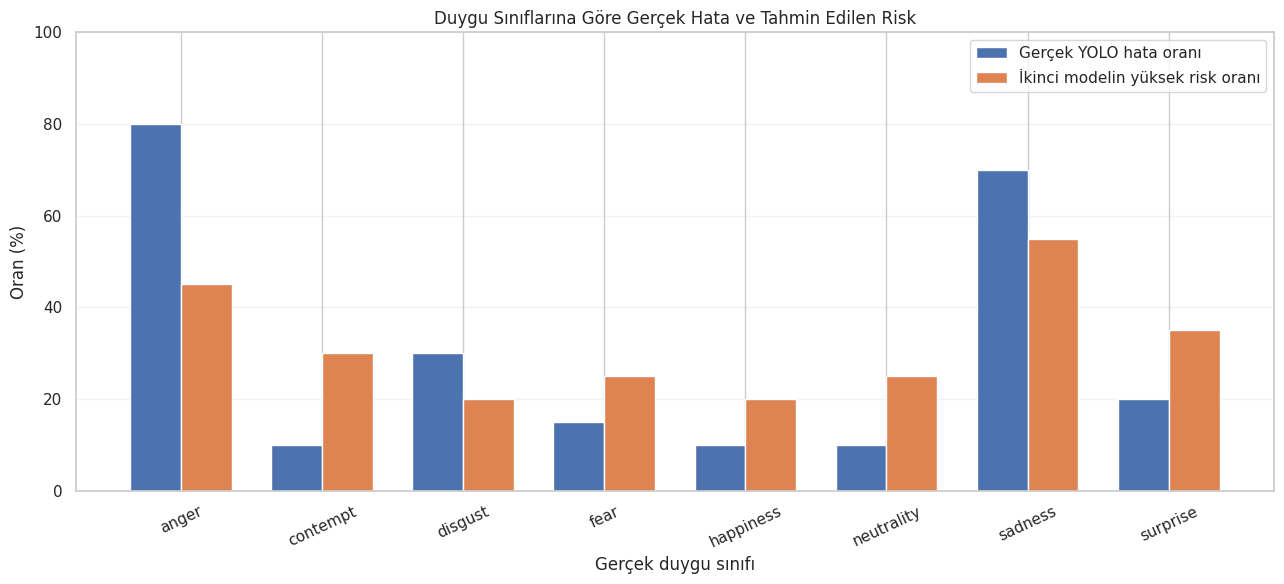

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

emotion_order = [
    "anger", "contempt", "disgust", "fear",
    "happiness", "neutrality", "sadness", "surprise"
]

class_analysis = (
    analysis_df.groupby("emotion")
    .agg(
        actual_error_rate=("actual_error", "mean"),
        predicted_high_risk_rate=("predicted_error", "mean")
    )
    .reindex(emotion_order) * 100
)

x = np.arange(len(emotion_order))
width = 0.36

plt.figure(figsize=(13, 6))

plt.bar(
    x - width/2,
    class_analysis["actual_error_rate"],
    width,
    label="Gerçek YOLO hata oranı"
)

plt.bar(
    x + width/2,
    class_analysis["predicted_high_risk_rate"],
    width,
    label="İkinci modelin yüksek risk oranı"
)

plt.xticks(x, emotion_order, rotation=25)
plt.ylabel("Oran (%)")
plt.xlabel("Gerçek duygu sınıfı")
plt.title("Duygu Sınıflarına Göre Gerçek Hata ve Tahmin Edilen Risk")
plt.ylim(0, 100)
plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

plt.savefig("siniflara_gore_hata_ve_risk.png", dpi=300)
plt.show()

İkinci modelin hata tahmin karışıklık matrisi
*   Gerçek hata + yüksek risk: Hata yakalandı.
*   Gerçek hata + düşük risk: Hata kaçırıldı.
*   Gerçek doğru + yüksek risk: Yanlış alarm.
*   Gerçek doğru + düşük risk: Doğru değerlendirme.

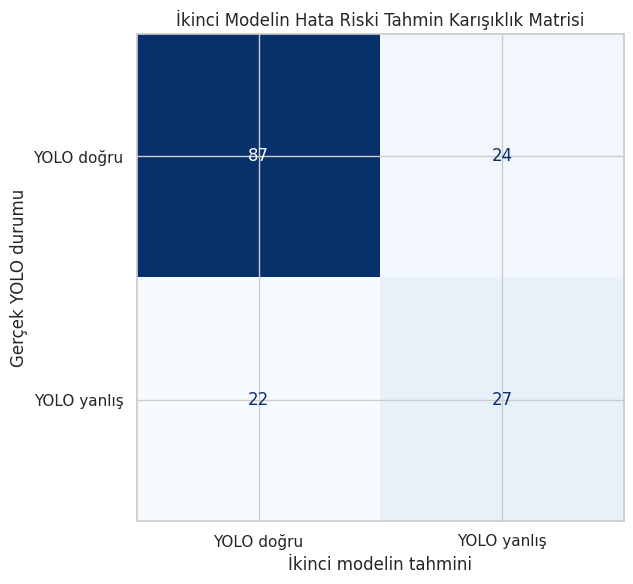

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    analysis_df["actual_error"],
    analysis_df["predicted_error"],
    labels=[0, 1]
)

display_labels = ["YOLO doğru", "YOLO yanlış"]

fig, ax = plt.subplots(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=display_labels
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("İkinci Modelin Hata Riski Tahmin Karışıklık Matrisi")
plt.xlabel("İkinci modelin tahmini")
plt.ylabel("Gerçek YOLO durumu")
plt.tight_layout()

plt.savefig("hata_riski_karisiklik_matrisi.png", dpi=300)
plt.show()

Gerçek hata durumuna göre risk skorları

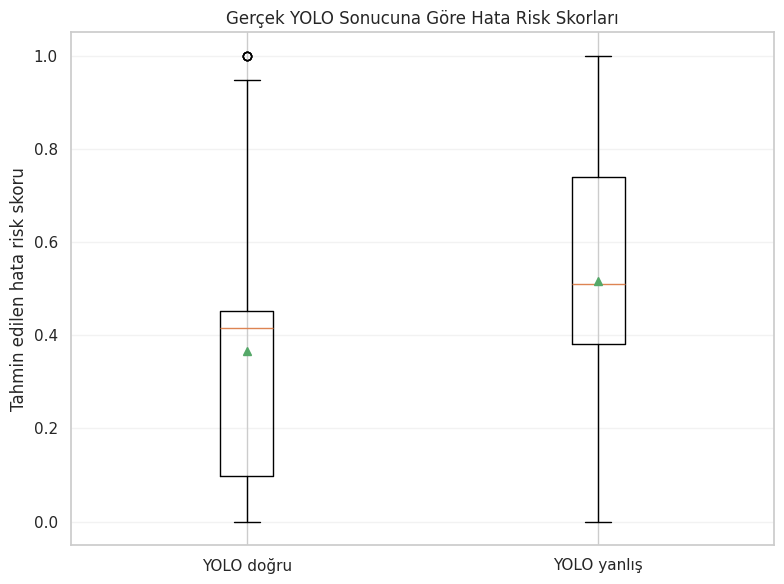

In [ ]:
plt.figure(figsize=(8, 6))

risk_correct = analysis_df.loc[
    analysis_df["actual_error"] == 0,
    "predicted_risk_probability"
]

risk_incorrect = analysis_df.loc[
    analysis_df["actual_error"] == 1,
    "predicted_risk_probability"
]

plt.boxplot(
    [risk_correct, risk_incorrect],
    tick_labels=["YOLO doğru", "YOLO yanlış"],
    showmeans=True
)

plt.ylabel("Tahmin edilen hata risk skoru")
plt.title("Gerçek YOLO Sonucuna Göre Hata Risk Skorları")
plt.ylim(-0.05, 1.05)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

plt.savefig("gercek_duruma_gore_risk_skorlari.png", dpi=300)
plt.show()